# Proyecto Final · Notebook Matriz (Estimación de Niveles de Obesidad)

**Equipo:** Sebastián Giraldo, Violeta España, Luis Murillo, Juan David Velasco & David Vergara  
**Dataset:** *Estimation of Obesity Levels Based on Eating Habits and Physical Condition* (UCI ID `544`)

Este cuaderno integra de forma unificada y reproducible las partes ya completadas en el repositorio (`develop`):
1. **EDA, limpieza, codificación y división 80/20** (`Desarrollo.ipynb`, `SEMILLA = 20`, 2,087 registros sin duplicados).
2. **Preprocesamientos:** **P1** (`RobustScaler`) y **P2** (`src/p2_habitos.py`: Ingeniería de Hábitos + Yeo-Johnson + `StandardScaler`). *(Pendiente de enchufar: **P3 · PCA 95 %**).*
3. **Modelos supervisados (mismo hardware y mismo protocolo 5-Fold CV):** **M1 (`RandomForestClassifier`)** y **M3 (`MLPClassifier`)** evaluados sobre `P1` y `P2`, con controles (*sin `Gender`* y *Operativo*), análisis de complejidad y exportación de pesos a Google Drive. *(Pendiente de enchufar: **M2 · XGBoost**).*

Para este proyecto seleccionamos el dataset *"Estimation of Obesity Levels Based on Eating Habits and Physical Condition"*, publicado en el repositorio UCI. Reúne 2.111 registros de personas de Colombia, México y Perú, con 17 variables sobre sus datos físicos, hábitos de alimentación, actividad física y antecedentes familiares. Cada persona está clasificada en uno de siete niveles de peso, desde peso insuficiente hasta obesidad tipo III.

### Librerías y Configuraciones

In [29]:
import json
import subprocess
import sys
import tempfile
import time
import warnings
from datetime import datetime
from pathlib import Path

# Instalación automática en Google Colab si faltan ucimlrepo o shap
try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"])
    from ucimlrepo import fetch_ucirepo

try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy import stats
from scipy.stats import chi2_contingency, skew, spearmanr

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
    validation_curve,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    MinMaxScaler,
    PowerTransformer,
    RobustScaler,
    StandardScaler,
)

# Importación de P2 desde src/p2_habitos.py (si se corre suelto en Colab, crea src/p2_habitos.py idéntico al repo)
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

_ruta_p2 = Path("src/p2_habitos.py")
if not _ruta_p2.exists():
    _ruta_p2.parent.mkdir(parents=True, exist_ok=True)
    Path("src/__init__.py").touch()
    _ruta_p2.write_text('"""Metodología de preprocesamiento P2: Ingeniería de Hábitos + Yeo-Johnson + StandardScaler.\n\nP2 está pensada para el benchmark preventivo (17 variables, sin Weight, Height ni IMC):\n1. Agrega 4 variables de dominio construidas solo con hábitos (fila a fila, sin parámetros\n   aprendidos, por lo que no hay fuga entre entrenamiento y prueba).\n2. Corrige la asimetría de las variables no binarias con Yeo-Johnson.\n3. Escala todas las variables (21 en total) a media 0 y desviación 1.\n\nTodo se encapsula en un `Pipeline` de sklearn para que se ajuste solo con entrenamiento.\n"""\nfrom typing import List\n\nimport pandas as pd\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import FunctionTransformer, PowerTransformer, StandardScaler\n\nHABIT_FEATURES = ["Balance_Act_Sed", "Hidratacion_Activa", "Riesgo_Gen_Cal", "Indice_Protector"]\n\n# Variables antropométricas: la clase se calcula con ellas, así que su presencia sería fuga\nFORBIDDEN_COLUMNS = ["Weight", "Height", "IMC"]\n\n\ndef agregar_habitos(X: pd.DataFrame) -> pd.DataFrame:\n    """Devuelve una copia de X con las 4 variables de hábitos agregadas.\n\n    - Balance_Act_Sed    = FAF / (TUE + 1): actividad física frente a tiempo frente a pantallas.\n    - Hidratacion_Activa = CH2O * (FAF + 1): consumo de agua potenciado por la actividad física.\n      (No se divide por Weight: eso filtra la clase).\n    - Riesgo_Gen_Cal     = family_history_with_overweight * FAVC: antecedente familiar y\n      consumo frecuente de comida calórica a la vez.\n    - Indice_Protector   = FCVC + CH2O + FAF + SCC - FAVC: suma de hábitos protectores menos\n      el consumo calórico. Los signos son supuestos porque la fórmula original llegó truncada;\n      pendiente de confirmar con Sebastián.\n\n    Lanza ValueError si X contiene Weight, Height o IMC: P2 es solo para el benchmark\n    preventivo y así se evita la fuga de información.\n    """\n    presentes = [c for c in FORBIDDEN_COLUMNS if c in X.columns]\n    if presentes:\n        raise ValueError(\n            f"P2 no admite variables antropométricas (fuga de la clase): {presentes}")\n\n    X = X.copy()\n    X["Balance_Act_Sed"] = X["FAF"] / (X["TUE"] + 1)\n    X["Hidratacion_Activa"] = X["CH2O"] * (X["FAF"] + 1)\n    X["Riesgo_Gen_Cal"] = X["family_history_with_overweight"] * X["FAVC"]\n    X["Indice_Protector"] = X["FCVC"] + X["CH2O"] + X["FAF"] + X["SCC"] - X["FAVC"]\n    return X\n\n\ndef _nombres_con_habitos(transformer, input_features) -> List[str]:\n    """Nombres de salida del paso de hábitos: las columnas de entrada más las 4 nuevas."""\n    return list(input_features) + HABIT_FEATURES\n\n\ndef columnas_continuas(X: pd.DataFrame) -> List[str]:\n    """Columnas con más de 2 valores distintos (no binarias ni one-hot)."""\n    return [c for c in X.columns if X[c].nunique() > 2]\n\n\ndef construir_p2(X_train_ejemplo: pd.DataFrame) -> Pipeline:\n    """Construye (sin ajustar) el pipeline P2.\n\n    Escala con StandardScaler (21 variables): las continuas pasan por Yeo-Johnson con\n    `standardize=True`, que ya las deja con media 0 y desviación 1; el resto (binarias y\n    one-hot) pasa por StandardScaler. Las columnas continuas se detectan sobre\n    `X_train_ejemplo` (con los hábitos agregados), por lo que debe ser el conjunto de\n    entrenamiento. El pipeline se ajusta después con `fit(X_train)`.\n    """\n    continuas = columnas_continuas(agregar_habitos(X_train_ejemplo))\n    transformacion = ColumnTransformer(\n        [("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=True), continuas)],\n        remainder=StandardScaler(),\n        verbose_feature_names_out=False,\n    )\n    return Pipeline([\n        ("habitos", FunctionTransformer(agregar_habitos, feature_names_out=_nombres_con_habitos)),\n        ("transformacion", transformacion),\n    ])\n', encoding="utf-8")

from src.p2_habitos import (
    FORBIDDEN_COLUMNS,
    HABIT_FEATURES,
    agregar_habitos,
    columnas_continuas,
    construir_p2,
)

# Configuraciones globales
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

AZUL, NARANJA = "#2a6fb0", "#d95f02"
SEMILLA = 20
np.random.seed(SEMILLA)

print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | seaborn {sns.__version__} | semilla = {SEMILLA}")

scikit-learn 1.6.1 | pandas 2.2.3 | seaborn 0.13.2 | semilla = 20


### Importar el Dataset del repositorio de UCI

In [30]:
# Descargar dataset oficial de UCI (id=544)
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544)

# Datos como DataFrames de pandas
X = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets

### Visualización de los datos

In [31]:
dataset = pd.concat([X, y], axis=1)
print("Dimensiones:", dataset.shape)
dataset.head()

Dimensiones: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000,1.620,64.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,0.000,1.000,no,Public_Transportation,Normal_Weight
1,Female,21.000,1.520,56.000,yes,no,3.000,3.000,Sometimes,yes,3.000,yes,3.000,0.000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000,1.800,77.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,2.000,1.000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000,1.800,87.000,no,no,3.000,3.000,Sometimes,no,2.000,no,2.000,0.000,Frequently,Walking,Overweight_Level_I
4,Male,22.000,1.780,89.800,no,no,2.000,1.000,Sometimes,no,2.000,no,0.000,0.000,Sometimes,Public_Transportation,Overweight_Level_II


In [32]:
def resumen(df):
    # Ficha técnica por columna: tipo, nulos, cardinalidad y un ejemplo
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

In [33]:
resumen(dataset)

,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Gender,object,2111,0,0.000,2,Female
Age,float64,2111,0,0.000,1402,21.000
Height,float64,2111,0,0.000,1574,1.620
Weight,float64,2111,0,0.000,1525,64.000
family_history_with_overweight,object,2111,0,0.000,2,yes
FAVC,object,2111,0,0.000,2,no
FCVC,float64,2111,0,0.000,810,2.000
NCP,float64,2111,0,0.000,635,3.000
CAEC,object,2111,0,0.000,4,Sometimes
SMOKE,object,2111,0,0.000,2,no


**¿Qué representa cada característica?**

- *Hábitos de alimentación*

| Variable | Descripción | Valores |
|:---:|:---:|:---:|
| `FAVC` | Consumo frecuente de alimentos calóricos | Sí / No |
| `FCVC` | Consumo de verduras en las comidas | Nunca / A veces / Siempre |
| `NCP` | Comidas principales al día | Entre 1 y 2 / Tres / Más de tres |
| `CAEC` | Consumo de alimentos entre comidas | No / A veces / Frecuentemente / Siempre |
| `CH2O` | Consumo diario de agua | Menos de 1 L / Entre 1 y 2 L / Más de 2 L |
| `CALC` | Consumo de alcohol | No bebo / A veces / Frecuentemente / Siempre |

- *Condición física y estilo de vida*

| Variable | Descripción | Valores |
|:---:|:---:|:---:|
| `SMOKE` | Fuma | Sí / No |
| `SCC` | Controla las calorías que consume | Sí / No |
| `FAF` | Frecuencia de actividad física | No hago / 1–2 días / 2–4 días / 4–5 días por semana |
| `TUE` | Tiempo diario frente a dispositivos electrónicos | 0–2 h / 3–5 h / Más de 5 h |
| `MTRANS` | Medio de transporte habitual | Automóvil / Moto / Bicicleta / Transporte público / Caminar |

### Revisión de duplicados y valores fuera del rango

In [34]:
# Registros duplicadas
n_dup = dataset.duplicated().sum()
print(f"\nRegistros duplicadas: {n_dup} ({n_dup / len(dataset):.1%} del total)")

# Ver cuáles son (keep=False muestra todas las copias, no solo las repetidas)
duplicados = dataset[dataset.duplicated(keep=False)]
print(f"Registros involucrados (originales + copias): {len(duplicados)}")
print("\nClase de los duplicados:")
print(dataset[dataset.duplicated()]["NObeyesdad"].value_counts())

# Valores fuera de rango (coherencia con la encuesta)
rangos = {"Age": (10, 100), "Height": (1.20, 2.20), "Weight": (30, 250),   # rangos fisiológicamente plausibles
          "FCVC": (1, 3), "NCP": (1, 4), "CH2O": (1, 3), "FAF": (0, 3), "TUE": (0, 2)}
print("\nValores fuera del rango esperado:")
for col, (mn, mx) in rangos.items():
    fuera = ((dataset[col] < mn) | (dataset[col] > mx)).sum()
    print(f"  {col:7s} rango [{mn}, {mx}] -> {fuera} fuera de rango")

# Categorías incorrectas en las variables de texto
print("\nCategorías de las variables de texto:")
for col in dataset.select_dtypes(include=["object", "string"]).columns:
    print(f"  {col:32s} {sorted(dataset[col].unique().tolist())}")


Registros duplicadas: 24 (1.1% del total)
Registros involucrados (originales + copias): 33

Clase de los duplicados:
NObeyesdad
Overweight_Level_I     14
Insufficient_Weight     5
Normal_Weight           5
Name: count, dtype: int64

Valores fuera del rango esperado:
  Age     rango [10, 100] -> 0 fuera de rango
  Height  rango [1.2, 2.2] -> 0 fuera de rango
  Weight  rango [30, 250] -> 0 fuera de rango
  FCVC    rango [1, 3] -> 0 fuera de rango
  NCP     rango [1, 4] -> 0 fuera de rango
  CH2O    rango [1, 3] -> 0 fuera de rango
  FAF     rango [0, 3] -> 0 fuera de rango
  TUE     rango [0, 2] -> 0 fuera de rango

Categorías de las variables de texto:
  Gender                           ['Female', 'Male']
  family_history_with_overweight   ['no', 'yes']
  FAVC                             ['no', 'yes']
  CAEC                             ['Always', 'Frequently', 'Sometimes', 'no']
  SMOKE                            ['no', 'yes']
  SCC                              ['no', 'yes']
  CALC    

### Validación de relación entre IMC y Target

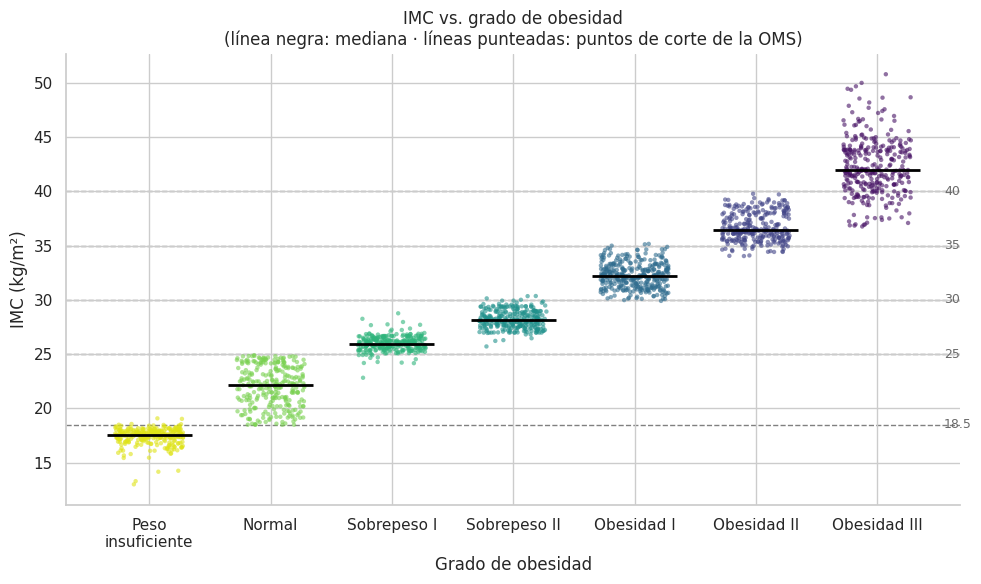

In [35]:
dataset['IMC'] = dataset['Weight'] / dataset['Height']**2

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
colores = plt.cm.viridis_r(np.linspace(0.05, 0.95, 7))

fig, ax = plt.subplots(figsize=(10, 6))
rng = np.random.default_rng(0)
for i, (clase, color) in enumerate(zip(orden, colores)):
    imc = dataset.loc[dataset['NObeyesdad'] == clase, 'IMC']
    x = i + rng.uniform(-0.28, 0.28, len(imc))   # dispersión horizontal para que no se encimen
    ax.scatter(x, imc, s=10, color=color, alpha=0.6, edgecolor='none')
    ax.hlines(imc.median(), i - 0.35, i + 0.35, color='black', linewidth=2)   # mediana

# Puntos de corte de la OMS
for v in [18.5, 25, 30, 35, 40]:
    ax.axhline(v, color='gray', linestyle='--', linewidth=1, zorder=0)
    ax.text(6.55, v, f'{v}', va='center', fontsize=9, color='dimgray')

ax.set_xticks(range(7), etiquetas)
ax.set_xlabel('Grado de obesidad')
ax.set_ylabel('IMC (kg/m²)')
ax.set_title('IMC vs. grado de obesidad\n(línea negra: mediana · líneas punteadas: puntos de corte de la OMS)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

- **Observación**

El IMC aumenta de forma escalonada con cada nivel de obesidad, y casi todos los registros caen dentro de la franja de la OMS que les corresponde (95,2 % de coincidencia). Esto confirma que la variable objetivo se construyó a partir del IMC. Por tanto, si el modelo recibe el peso y la estatura, solo aprendería a recalcular el IMC. Por esta razón se realizó un análisis adicional para evaluar si se debía considerar o no esas características.

### Válidación de balance de clases

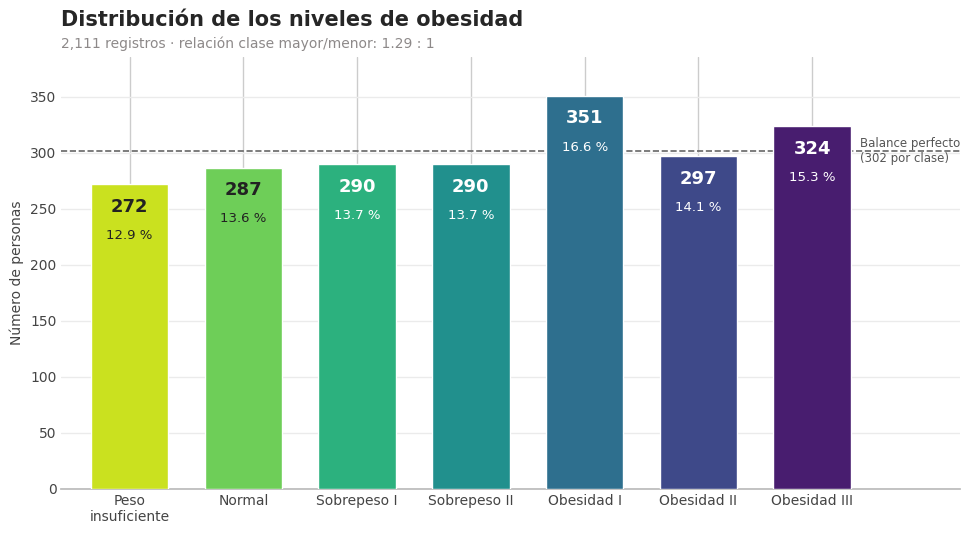

In [36]:
import numpy as np
import matplotlib.pyplot as plt

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
conteo = dataset['NObeyesdad'].value_counts().reindex(orden)
porcentaje = conteo / len(dataset) * 100

# Paleta ordenada: de amarillo-verde (peso bajo) a morado (obesidad III)
colores = plt.cm.viridis_r(np.linspace(0.08, 0.92, len(orden)))

fig, ax = plt.subplots(figsize=(10, 5.5))
barras = ax.bar(etiquetas, conteo.values, color=colores, width=0.68, zorder=3)

# Número y porcentaje dentro de cada barra
for barra, n, p, c in zip(barras, conteo.values, porcentaje.values, colores):
    x = barra.get_x() + barra.get_width() / 2
    lum = 0.299*c[0] + 0.587*c[1] + 0.114*c[2]
    texto = '#222222' if lum > 0.55 else 'white'      # texto oscuro en barras claras
    ax.text(x, n - 12, f'{n}', ha='center', va='top', fontsize=13, fontweight='bold', color=texto, zorder=5)
    ax.text(x, n - 40, f'{p:.1f} %', ha='center', va='top', fontsize=9.5, color=texto, zorder=5)

# Línea de balance perfecto (queda detrás de las barras)
ideal = len(dataset) / len(orden)
ax.axhline(ideal, color='#666666', linestyle='--', linewidth=1.2, zorder=2)
ax.text(6.42, ideal, f'Balance perfecto\n({ideal:.0f} por clase)', va='center', fontsize=8.5, color='#555555')

ax.set_title('Distribución de los niveles de obesidad', fontsize=15, fontweight='bold', loc='left', pad=22)
ax.text(0, 1.02, f'{len(dataset):,} registros · relación clase mayor/menor: {conteo.max()/conteo.min():.2f} : 1',
        transform=ax.transAxes, fontsize=10, color="#8D8989")
ax.set_ylabel('Número de personas', fontsize=10, color='#444444')
ax.set_ylim(0, conteo.max() * 1.1)
ax.set_xlim(-0.6, 7.3)
ax.grid(axis='y', color = '#ebebeb', zorder=0)
ax.tick_params(axis='both', length=0, labelsize=10, colors='#444444')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#bbbbbb')
plt.tight_layout()
plt.show()

El dataset está balanceado. La clase más grande (Obesidad I) tiene apenas 1,29 veces los registros de la más pequeña (Peso insuficiente). Todas quedan cerca del 14,3 % que tendría un balance perfecto, que es la línea punteada de la gráfica.

### Análisis univariado de las variables númericas

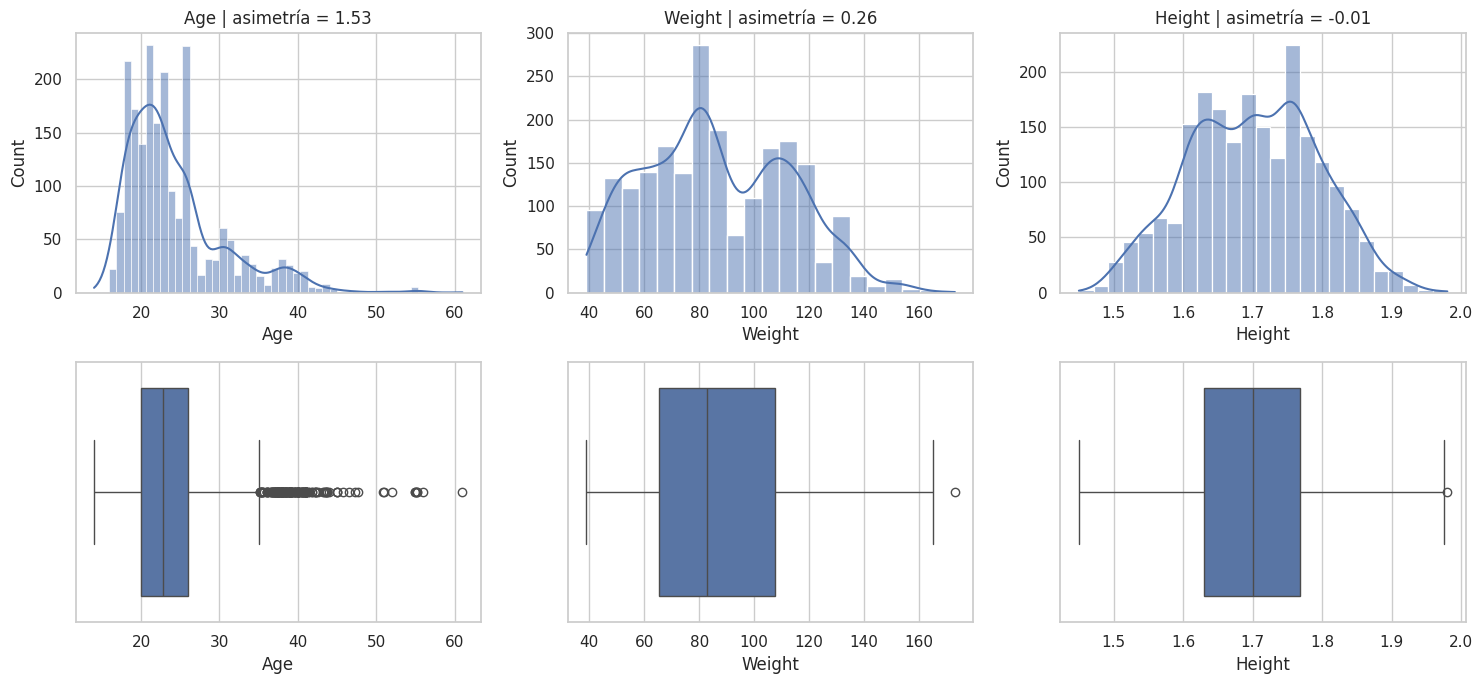

In [37]:
numericas = ["Age", "Weight", "Height"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(numericas):
    sns.histplot(dataset[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} | asimetría = {dataset[col].skew():.2f}")
    sns.boxplot(x=dataset[col], ax=axes[1, i])
plt.tight_layout(); plt.show()

#### Observaciones

- *Age* tiene asimetría positiva fuerte (1,53). La mayoría de los encuestados son jóvenes: el 76 % tiene 26 años o menos y la mediana es 22,8. La cola se extiende hasta 61 años. El boxplot marca 168 valores atípicos, todos por encima de unos 35 años. No son errores: son personas mayores que simplemente son pocas en la muestra, así que no hay que eliminarlas. Para el informe, esto significa que los resultados representan sobre todo a población joven.
- *Weight* es casi simétrica (0,26), pero tiene varios picos. Eso tiene sentido, porque mezcla personas de 7 niveles de peso distintos. Solo hay un atípico, de 173 kg, y es un valor plausible.
- *Height* es prácticamente normal (−0,01), con una forma de campana centrada en 1,70 m y sin atípicos relevantes.

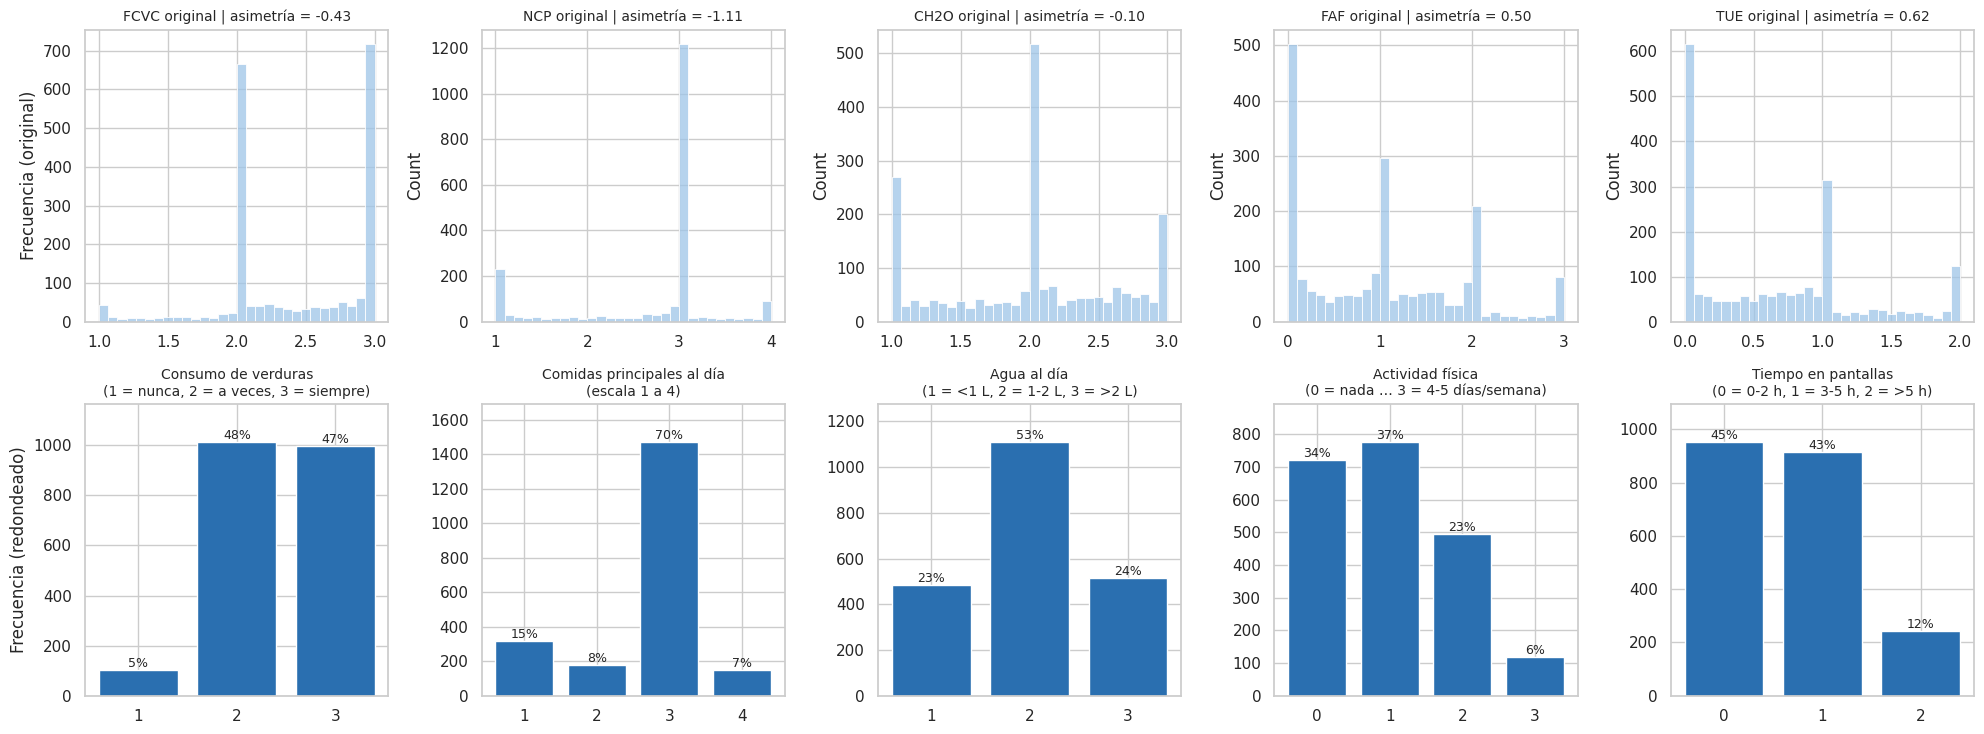

In [38]:
ordinales = {
    "FCVC": "Consumo de verduras\n(1 = nunca, 2 = a veces, 3 = siempre)",
    "NCP":  "Comidas principales al día\n(escala 1 a 4)",
    "CH2O": "Agua al día\n(1 = <1 L, 2 = 1-2 L, 3 = >2 L)",
    "FAF":  "Actividad física\n(0 = nada … 3 = 4-5 días/semana)",
    "TUE":  "Tiempo en pantallas\n(0 = 0-2 h, 1 = 3-5 h, 2 = >5 h)",
}

fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for i, (col, titulo) in enumerate(ordinales.items()):
    # Fila 1: valores originales (con decimales sintéticos)
    sns.histplot(dataset[col], bins=30, ax=axes[0, i], color='#9ec5e8')
    axes[0, i].set_title(f"{col} original | asimetría = {dataset[col].skew():.2f}", fontsize=10)
    axes[0, i].set_xlabel('')

    # Fila 2: valores redondeados a la escala de la encuesta
    conteo = dataset[col].round().astype(int).value_counts().sort_index()
    barras = axes[1, i].bar(conteo.index.astype(str), conteo.values, color='#2a6fb0')
    axes[1, i].bar_label(barras, labels=[f'{v/len(dataset):.0%}' for v in conteo.values], fontsize=9)
    axes[1, i].set_title(titulo, fontsize=10)
    axes[1, i].set_ylim(0, conteo.max() * 1.15)

axes[0, 0].set_ylabel('Frecuencia (original)')
axes[1, 0].set_ylabel('Frecuencia (redondeado)')
plt.tight_layout(); plt.show()


#### Observaciones

- *FCVC, verduras*: casi nadie dice “nunca” (5 %). El resto se reparte entre “a veces” (48 %) y “siempre” (47 %).
NCP, comidas al día: la gran mayoría responde 3 (70 %). Es la variable menos variada, así que probablemente aporte poco para distinguir clases.
- *CH2O, agua*: la distribución es la más equilibrada. La mitad toma entre 1 y 2 litros (53 %).
- *FAF, actividad física*: el 34 % no hace nada de ejercicio y solo el 6 % hace 4 o 5 días por semana. Puede ser de las variables más útiles para el modelo.
- *TUE, pantallas*: la mayoría pasa 0–2 h (45 %) o 3–5 h (43 %) frente a pantallas, y solo el 12 % más de 5 h.


### Análisis bivariado

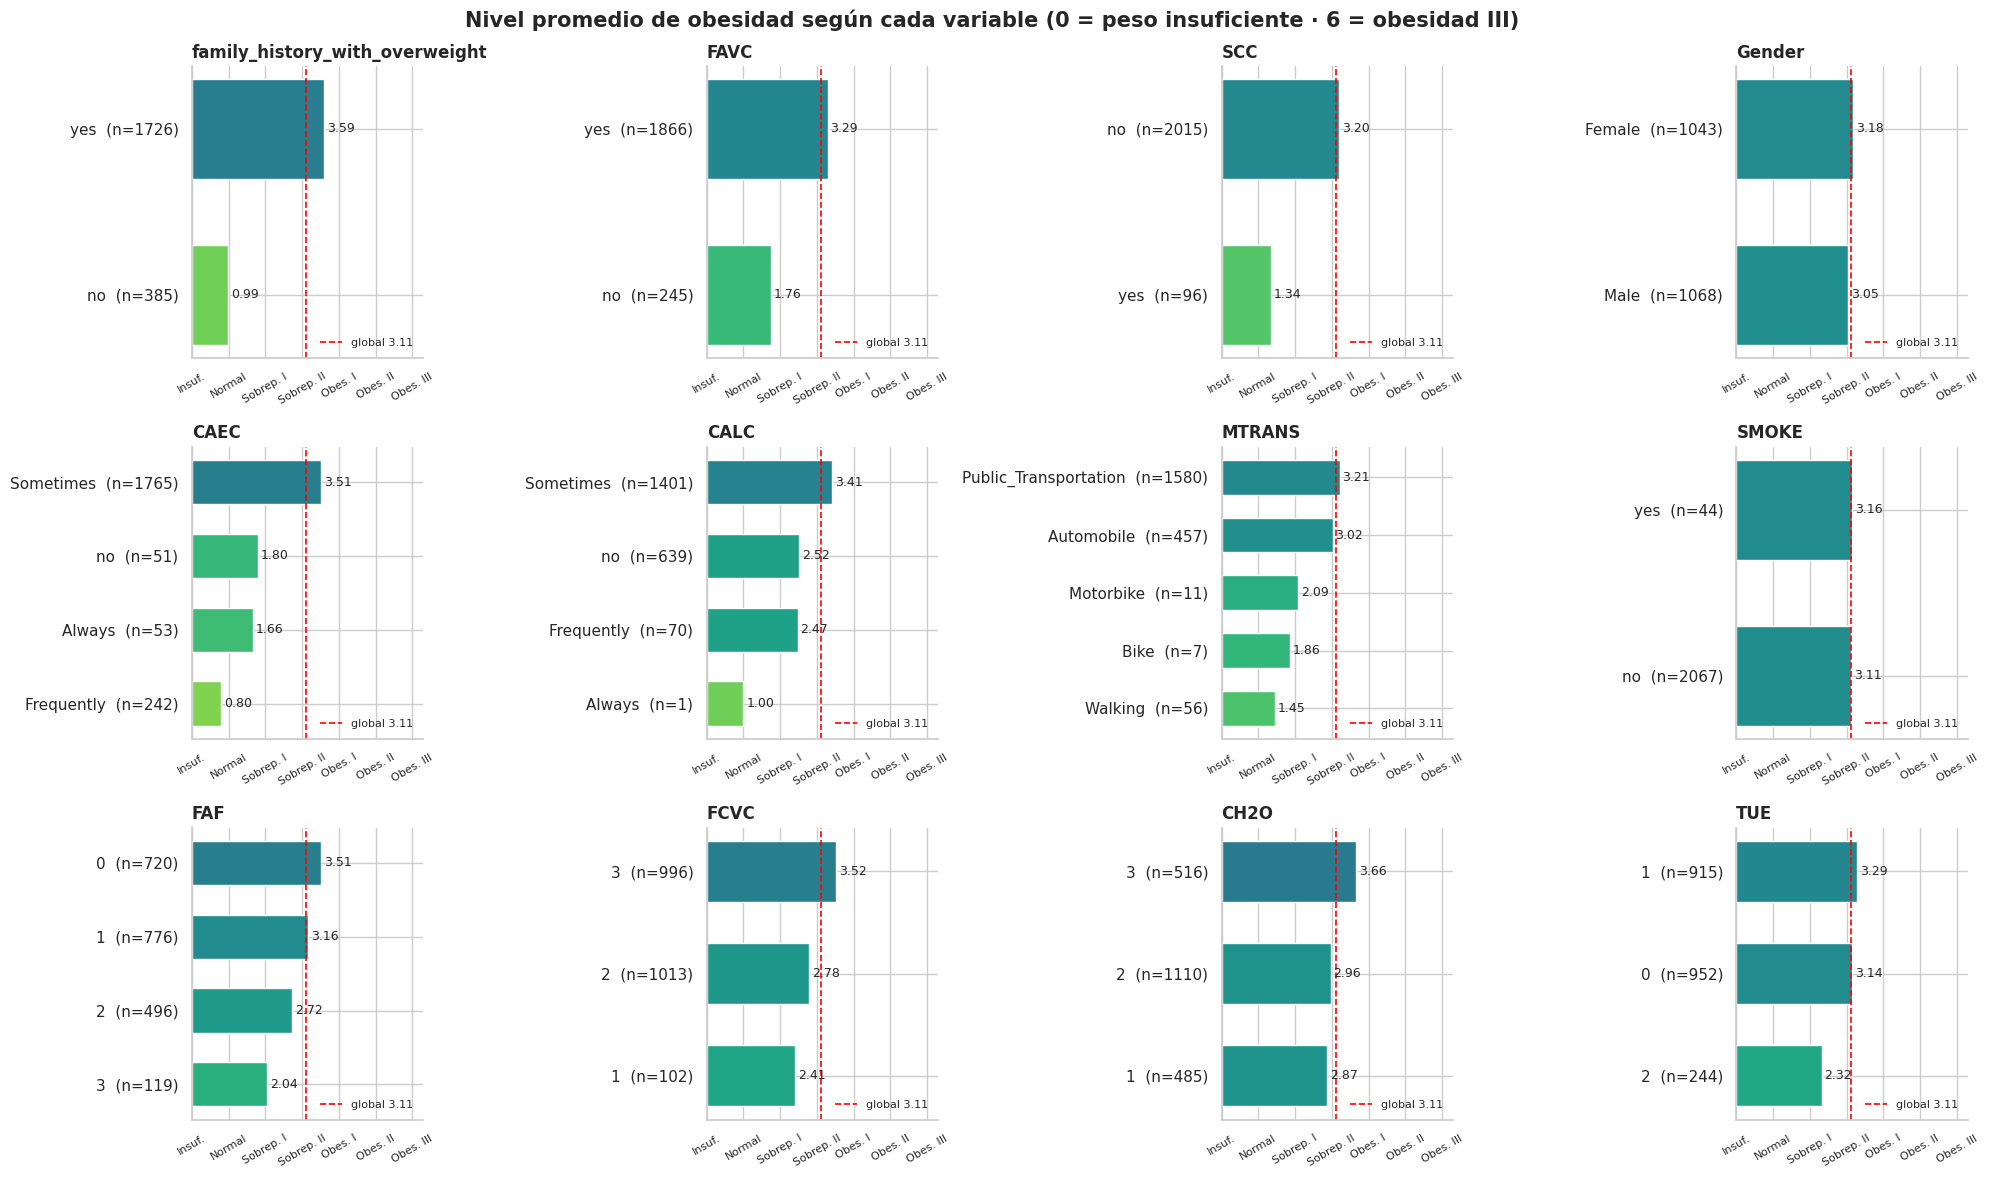

In [39]:
import matplotlib.pyplot as plt

# Codificación ordinal del objetivo: 0 = peso insuficiente ... 6 = obesidad III
niveles = {'Insufficient_Weight': 0, 'Normal_Weight': 1, 'Overweight_Level_I': 2,
           'Overweight_Level_II': 3, 'Obesity_Type_I': 4, 'Obesity_Type_II': 5, 'Obesity_Type_III': 6}
nombres_cortos = ['Insuf.', 'Normal', 'Sobrep. I', 'Sobrep. II', 'Obes. I', 'Obes. II', 'Obes. III']
dataset["nivel"] = dataset["NObeyesdad"].map(niveles)
nivel_global = dataset["nivel"].mean()

dataset_biv = dataset.copy()
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    dataset_biv[col] = dataset_biv[col].round().astype(int)

variables = ["family_history_with_overweight", "FAVC", "SCC", "Gender",
             "CAEC", "CALC", "MTRANS", "SMOKE",
             "FAF", "FCVC", "CH2O", "TUE"]
cmap = plt.cm.viridis_r

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.ravel(), variables):
    grupo = dataset_biv.groupby(col)["nivel"].agg(["mean", "size"]).sort_values("mean")
    etiquetas = [f"{c}  (n={n})" for c, n in zip(grupo.index.astype(str), grupo["size"])]
    colores = cmap(0.08 + 0.84 * grupo["mean"].values / 6)   # el color refleja el nivel promedio
    ax.barh(etiquetas, grupo["mean"].values, color=colores, height=0.6)
    for y, v in enumerate(grupo["mean"].values):
        ax.text(v + 0.08, y, f"{v:.2f}", va="center", fontsize=9)
    ax.axvline(nivel_global, color="red", ls="--", lw=1.2, label=f"global {nivel_global:.2f}")
    ax.set_xlim(0, 6.3)
    ax.set_xticks(range(7), nombres_cortos, fontsize=8, rotation=30)
    ax.set_title(col, fontsize=12, fontweight="bold", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", fontsize=8, frameon=False)

fig.suptitle("Nivel promedio de obesidad según cada variable (0 = peso insuficiente · 6 = obesidad III)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

- **Observaciones**

La línea roja marca el nivel promedio global (3,11, cercano a Sobrepeso II). Las barras que la superan corresponden a grupos con más obesidad que el promedio, y las que no la alcanzan, a grupos con menos.

- *Antecedentes familiares*: es la variable con mayor diferencia. Quienes no tienen antecedentes promedian 0,99 (peso normal), mientras que quienes sí los tienen llegan a 3,59 (entre sobrepeso II y obesidad I).
- *Hábitos de control*: quienes controlan las calorías que consumen (`SCC`) promedian 1,34 frente a 3,20 de quienes no lo hacen. Algo similar ocurre con el consumo frecuente de comida calórica (`FAVC`): 1,76 sin el hábito y 3,29 con él.
- *Actividad física (`FAF`)*: muestra el patrón más coherente. El nivel baja a medida que aumenta el ejercicio, de 3,51 en quienes no hacen nada a 2,04 en quienes se ejercitan 4–5 días por semana.
- *Transporte (`MTRANS`)*: quienes caminan promedian 1,45, muy por debajo de quienes usan transporte público (3,21) o automóvil (3,02).
- *Relaciones contraintuitivas*: quienes comen verduras "siempre" (`FCVC`) o toman más de 2 L de agua (`CH2O`) tienen mayor nivel de obesidad (3,52 y 3,66), y quienes comen entre comidas "frecuentemente" (`CAEC`) tienen el nivel más bajo (0,80). Esto puede deberse a causalidad inversa (personas con obesidad que cambiaron sus hábitos por recomendación médica) o a artefactos del sobremuestreo sintético.
- *Género*: hombres (3,05) y mujeres (3,18) parecen iguales, pero el promedio esconde una diferencia importante: Obesidad II está compuesta casi solo por hombres y Obesidad III casi solo por mujeres. Esto se confirma con la V de Cramér.
- *Sin diferencia*: fumar (`SMOKE`) y el tiempo frente a pantallas (`TUE`) no muestran diferencias relevantes respecto al promedio.

Fianlmente, se puede notar que también hay categorías con muy pocos registros (`CALC = Always` con n = 1, `Bike` con n = 7 y `Motorbike` con n = 11) no permiten sacar conclusiones confiables.

### V de Cramer

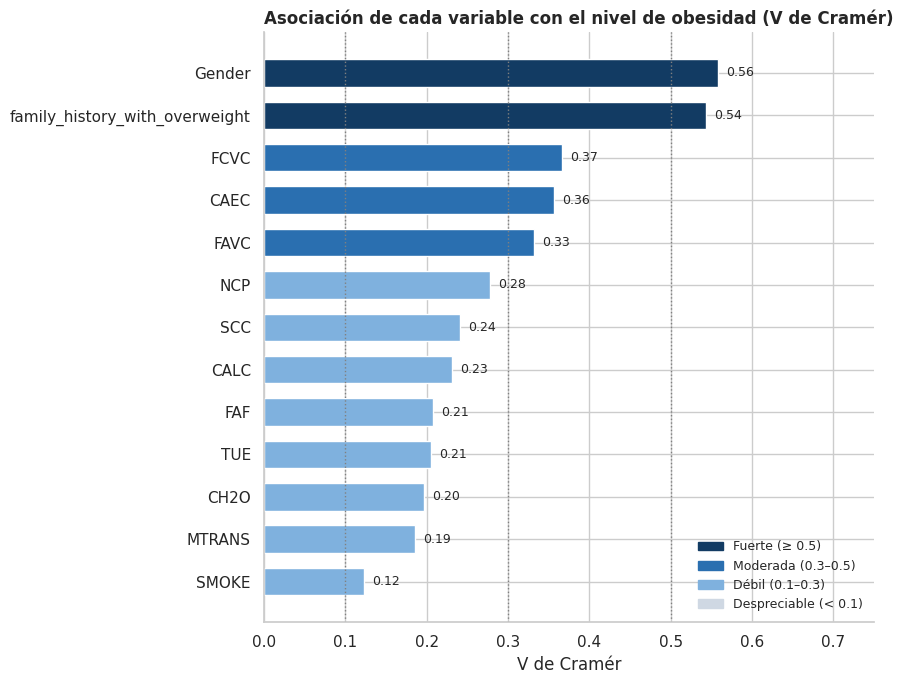

In [40]:
def v_cramer(x, y):
    tabla = pd.crosstab(x, y)
    chi2, p = chi2_contingency(tabla, correction=False)[:2]
    n = tabla.values.sum()
    r, k = tabla.shape
    return np.sqrt((chi2 / n) / (min(r, k) - 1)), p

# Ordinales numéricas redondeadas a su escala
dataset_cat = dataset.copy()
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    dataset_cat[col] = dataset_cat[col].round().astype(int)

cat_vars = [c for c in dataset_cat.select_dtypes(include=["object", "string"]).columns if c != "NObeyesdad"] \
           + ["FCVC", "NCP", "CH2O", "FAF", "TUE"]

resultados = pd.DataFrame(
    [v_cramer(dataset_cat[c], dataset_cat["NObeyesdad"]) for c in cat_vars],
    index=cat_vars, columns=["V de Cramér", "p-valor"]
).sort_values("V de Cramér")

# Gráfica coloreada por fuerza de asociación
def fuerza(v):
    return "Fuerte" if v >= 0.5 else "Moderada" if v >= 0.3 else "Débil" if v >= 0.1 else "Despreciable"
colores_fuerza = {"Fuerte": "#123b63", "Moderada": "#2a6fb0", "Débil": "#7fb1de", "Despreciable": "#cfd8e3"}
colores = [colores_fuerza[fuerza(v)] for v in resultados["V de Cramér"]]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(resultados.index, resultados["V de Cramér"], color=colores, height=0.65)
for y, v in enumerate(resultados["V de Cramér"]):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9)
for umbral in [0.1, 0.3, 0.5]:
    ax.axvline(umbral, color="gray", ls=":", lw=1)
ax.set_xlim(0, 0.75)
ax.set_xlabel("V de Cramér")
ax.set_title("Asociación de cada variable con el nivel de obesidad (V de Cramér)", loc="left", fontweight="bold")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_fuerza.values()],
          ["Fuerte (≥ 0.5)", "Moderada (0.3–0.5)", "Débil (0.1–0.3)", "Despreciable (< 0.1)"],
          loc="lower right", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [41]:
# Género por clase: evidencia del sesgo (Obesity_II casi solo hombres, Obesity_III casi solo mujeres)
orden_clases = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
                "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]
pd.crosstab(dataset["NObeyesdad"], dataset["Gender"]).reindex(orden_clases)

Gender,Female,Male
NObeyesdad,,
Insufficient_Weight,173,99
Normal_Weight,141,146
Overweight_Level_I,145,145
Overweight_Level_II,103,187
Obesity_Type_I,156,195
Obesity_Type_II,2,295
Obesity_Type_III,323,1


- **Observaciones**

Todas las asociaciones son estadísticamente significativas (p ≈ 0), así que lo que importa es su fuerza.

- *Antecedentes familiares* (0,54): es la variable fuerte con sentido real. Casi todas las personas con obesidad tipo I, II y III tienen familiares con sobrepeso.
- *FCVC*, *CAEC* y *FAVC* (0,33 a 0,37): asociación moderada (verduras, comida entre comidas y comida hipercalórica).
- *NCP*, *CALC*, *FAF*, *TUE*, *CH2O*, *MTRANS* y *SMOKE*: asociación débil. Individualmente aportan poco, pero pueden sumar en conjunto.
- ***Gender* (0,56) sale como la variable más fuerte, pero es un sesgo del dataset y no un hallazgo.** Obesidad II tiene 295 hombres y 2 mujeres; Obesidad III tiene 323 mujeres y 1 hombre. Esas clases tienen muy pocas personas reales (unas 11 y 3) y casi todas son sintéticas, generadas con SMOTE a partir de ellas, así que heredaron un género casi puro. En las filas reales el género se reparte parejo en todas las clases.

**Decisión pendiente:** hay que definir qué hacer con *Gender* en el modelo. Las opciones son (1) dejarlo, asumiendo el sesgo y dejándolo documentado; (2) quitarlo del benchmark preventivo; o (3) probar el modelo con y sin *Gender* (y comparar, idealmente también sobre las filas reales) para ver cuánto cambia el rendimiento y la interpretación con SHAP. Por ahora se mantiene en el preventivo, y el riesgo es que el modelo aprenda el atajo "hombre = Obesidad II, mujer = Obesidad III", que infle las métricas y que SHAP muestre el género como un factor de peso que no lo es.

### Codificación de variables categóricas de entrada

In [42]:
data = dataset.copy()

# Binarias
data["Gender"] = data["Gender"].map({"Female": 0, "Male": 1})
for col in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    data[col] = data[col].map({"no": 0, "yes": 1})

# Ordinales
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    data[col] = data[col].round().astype(int)

orden_frecuencia = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
data["CAEC"] = data["CAEC"].map(orden_frecuencia)
data["CALC"] = data["CALC"].replace("Always", "Frequently")   # "Always" tiene 1 solo registro
data["CALC"] = data["CALC"].map(orden_frecuencia)

# Nominales
data["MTRANS"] = data["MTRANS"].replace({"Bike": "Two_Wheels", "Motorbike": "Two_Wheels"})  # 7 y 11 casos
data = pd.get_dummies(data, columns=["MTRANS"], prefix="MTRANS", dtype=int)

# Target: codificación ordinal de 0 a 6 (peso insuficiente … obesidad III)
niveles = {
    "Insufficient_Weight": 0,
    "Normal_Weight": 1,
    "Overweight_Level_I": 2,
    "Overweight_Level_II": 3,
    "Obesity_Type_I": 4,
    "Obesity_Type_II": 5,
    "Obesity_Type_III": 6,
}
data["NObeyesdad"] = data["NObeyesdad"].map(niveles)
nombres_clases = {v: k for k, v in niveles.items()}   # para volver a nombres al mostrar resultados

# Verificación de la transformación
print(f"Dimensiones: {data.shape}")
print(f"Nulos totales: {data.isna().sum().sum()}")
print(f"Columnas no numéricas: {data.select_dtypes(exclude='number').columns.tolist()}")
print("\nValores únicos por columna (excepto continuas):")
for col in data.columns.drop(["Age", "Height", "Weight"]):
    print(f"  {col:32s} {sorted(data[col].unique().tolist())}")

data.head()

Dimensiones: (2111, 22)
Nulos totales: 0
Columnas no numéricas: []

Valores únicos por columna (excepto continuas):
  Gender                           [0, 1]
  family_history_with_overweight   [0, 1]
  FAVC                             [0, 1]
  FCVC                             [1, 2, 3]
  NCP                              [1, 2, 3, 4]
  CAEC                             [0, 1, 2, 3]
  SMOKE                            [0, 1]
  CH2O                             [1, 2, 3]
  SCC                              [0, 1]
  FAF                              [0, 1, 2, 3]
  TUE                              [0, 1, 2]
  CALC                             [0, 1, 2]
  NObeyesdad                       [0, 1, 2, 3, 4, 5, 6]
  IMC                              [12.998684889724604, 13.291587901701323, 14.160574669617416, 14.25387559306874, 15.432098765432098, 15.457234117286061, 15.665158448270383, 15.792641075006339, 15.822158933586486, 15.8592959374506, 15.905787660342869, 16.027529774529064, 16.088735295769812, 

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,NObeyesdad,IMC,nivel,MTRANS_Automobile,MTRANS_Public_Transportation,MTRANS_Two_Wheels,MTRANS_Walking
0,0,21.000,1.620,64.000,1,0,2,3,1,0,2,0,0,1,0,1,24.387,1,0,1,0,0
1,0,21.000,1.520,56.000,1,0,3,3,1,1,3,1,3,0,1,1,24.238,1,0,1,0,0
2,1,23.000,1.800,77.000,1,0,2,3,1,0,2,0,2,1,2,1,23.765,1,0,1,0,0
3,1,27.000,1.800,87.000,0,0,3,3,1,0,2,0,2,0,2,2,26.852,2,0,0,0,1
4,1,22.000,1.780,89.800,0,0,2,1,1,0,2,0,0,0,1,3,28.342,3,0,1,0,0


- **Observaciones**

Las variables binarias se codificaron como 0/1; las ordinales, respetando su orden; MTRANS con one-hot, agrupando bicicleta y moto por tener pocos casos; y el objetivo de 0 a 6. Las ordinales numéricas se redondearon a la escala original de la encuesta. La codificación se aplica antes de la división porque usa mapeos fijos que no dependen de los datos, por lo que no introduce fuga de información.

### Matriz de Spearman para Variables Numéricas

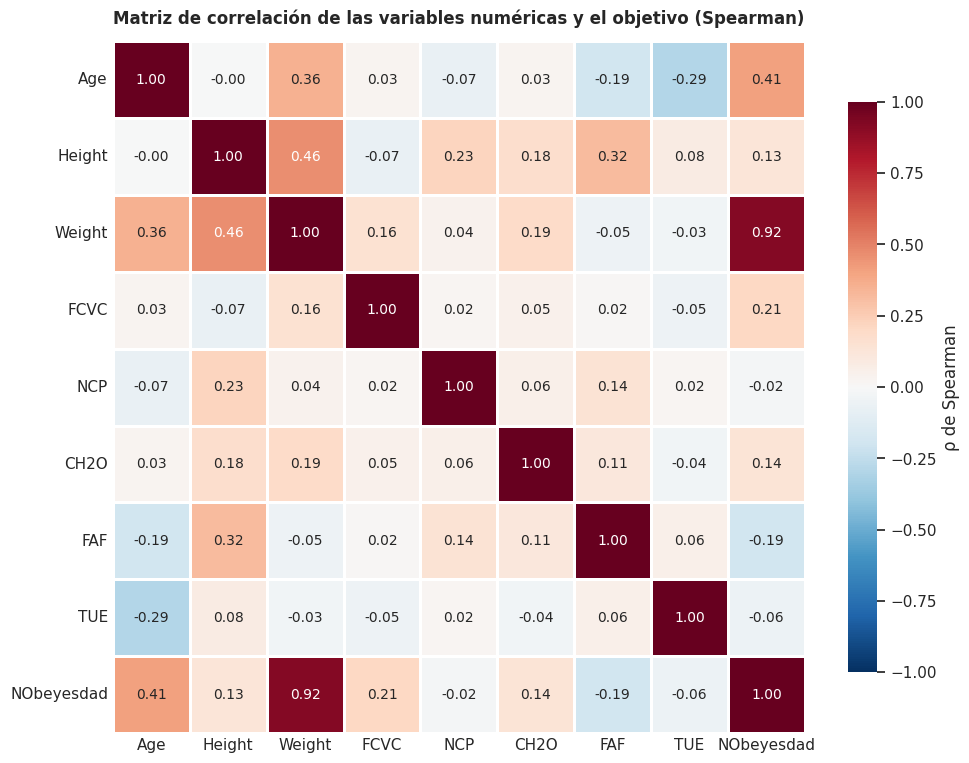

In [43]:
numericas = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE", "NObeyesdad"]
corr = data[numericas].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, linecolor="white", annot_kws={"size": 10},
            cbar_kws={"shrink": 0.8, "label": "ρ de Spearman"}, ax=ax)

ax.set_title("Matriz de correlación de las variables numéricas y el objetivo (Spearman)",
             loc="left", fontweight="bold", fontsize=12, pad=12)
ax.tick_params(length=0)
plt.xticks(rotation=0); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

### División del Dataset Train / Test

Se eliminan los duplicados y se dividen los datos 80/20 estratificado. Se arman dos conjuntos de variables con las mismas filas:

- **Preventivo (principal):** hábitos, antecedentes, edad y género. Sin peso, estatura ni IMC (fuga de información). *Gender* se mantiene por ahora, pero presenta un sesgo del dataset sintético (ver observaciones de la V de Cramér) y su uso está por decidir.
- **Operativo (referencia):** todas las variables más IMC, para medir el efecto de la fuga.

In [44]:
# Duplicados: se eliminan ANTES de dividir, para que una misma persona no quede en entrenamiento y en prueba
sin_dup = ~dataset.duplicated()
print(f"Duplicados eliminados: {(~sin_dup).sum()} ({len(dataset)} -> {sin_dup.sum()} registros)")
data_u = data[sin_dup]

# Nunca son variables de entrada: el target y 'nivel' (copia numérica del target, creada para graficar)
excluir = ["NObeyesdad", "nivel"]

# Benchmark preventivo (principal): hábitos, antecedentes, edad y género. Sin Weight, Height ni IMC (fuga: la clase se calcula con ellos)
# OJO: Gender tiene sesgo por el SMOTE (Obesity_II casi todo hombres, Obesity_III casi todo mujeres). Se mantiene por ahora; decisión pendiente
X_prev = data_u.drop(columns=excluir + ["Weight", "Height", "IMC"])
# Benchmark operativo (referencia): todas las variables + IMC, para medir el efecto de la fuga
X_oper = data_u.drop(columns=excluir)
y = data_u["NObeyesdad"]

# Un único split para ambos benchmarks (mismas filas, misma semilla)
idx_train, idx_test = train_test_split(
    y.index, test_size=0.2, stratify=y, random_state=SEMILLA)

X_train, X_test = X_prev.loc[idx_train], X_prev.loc[idx_test]               # preventivo
X_train_oper, X_test_oper = X_oper.loc[idx_train], X_oper.loc[idx_test]     # operativo
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# Verificación anti-fuga
assert not {"NObeyesdad", "nivel", "Weight", "Height", "IMC"} & set(X_train.columns), "Fuga en el preventivo"
assert not {"NObeyesdad", "nivel"} & set(X_train_oper.columns), "El target está en las variables de entrada"

print("\nPreventivo -> Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Operativo  -> Entrenamiento:", X_train_oper.shape, "| Prueba:", X_test_oper.shape)

# Proporción de cada clase en total, entrenamiento y prueba
proporciones = pd.DataFrame({
    "Total (%)": y.value_counts(normalize=True),
    "Entrenamiento (%)": y_train.value_counts(normalize=True),
    "Prueba (%)": y_test.value_counts(normalize=True),
}).sort_index()
proporciones.index = proporciones.index.map(nombres_clases)
print((proporciones * 100).round(1))

Duplicados eliminados: 24 (2111 -> 2087 registros)

Preventivo -> Entrenamiento: (1669, 17) | Prueba: (418, 17)
Operativo  -> Entrenamiento: (1669, 20) | Prueba: (418, 20)
                     Total (%)  Entrenamiento (%)  Prueba (%)
NObeyesdad                                                   
Insufficient_Weight     12.800             12.800      12.700
Normal_Weight           13.500             13.500      13.600
Overweight_Level_I      13.200             13.200      13.200
Overweight_Level_II     13.900             13.900      13.900
Obesity_Type_I          16.800             16.800      16.700
Obesity_Type_II         14.200             14.200      14.400
Obesity_Type_III        15.500             15.500      15.600


---
# Fase de Preprocesamiento: Metodologías Integradas (`P1` y `P2`)

Todos los preprocesadores reciben el `X_train` de referencia y devuelven un `Pipeline` sin ajustar para que sus parámetros se calculen **exclusivamente dentro de cada pliegue de entrenamiento** (cero fuga de datos).

- **P1 · Escalado Robusto (`RobustScaler`):** 17 variables limpias centradas con mediana ($Q_2$) y escaladas con $\text{IQR} = Q_3 - Q_1$.
- **P2 · Ingeniería de Hábitos + Yeo-Johnson + `StandardScaler` (`src/p2_habitos.py`):** 21 variables (4 índices conductuales sin peso ni estatura + transformación Yeo-Johnson en continuas + `StandardScaler`).
- **P3 · `RobustScaler` + `PCA 95%`:** *(pendiente por integrar en el diccionario `preprocesadores`)*.

=== Diagnóstico P1 · Escalado Robusto (solo entrenamiento) ===


,Antes · Mediana,Antes · IQR,"Antes · [Min, Max]",P1 · Mediana,P1 · IQR,"P1 · [Min, Max]"
Age,22.883,6.052,"[14.0, 61.0]",0.000,1.000,"[-1.47, 6.30]"
FCVC,2.000,1.000,"[1.0, 3.0]",0.000,1.000,"[-1.00, 1.00]"
NCP,3.000,0.000,"[1.0, 4.0]",0.000,0.000,"[-2.00, 1.00]"
CH2O,2.000,0.000,"[1.0, 3.0]",0.000,0.000,"[-1.00, 1.00]"
FAF,1.000,2.000,"[0.0, 3.0]",0.000,1.000,"[-0.50, 1.00]"
TUE,1.000,1.000,"[0.0, 2.0]",0.000,1.000,"[-1.00, 1.00]"
CAEC,1.000,0.000,"[0.0, 3.0]",0.000,0.000,"[-1.00, 2.00]"
CALC,1.000,1.000,"[0.0, 2.0]",0.000,1.000,"[-1.00, 1.00]"


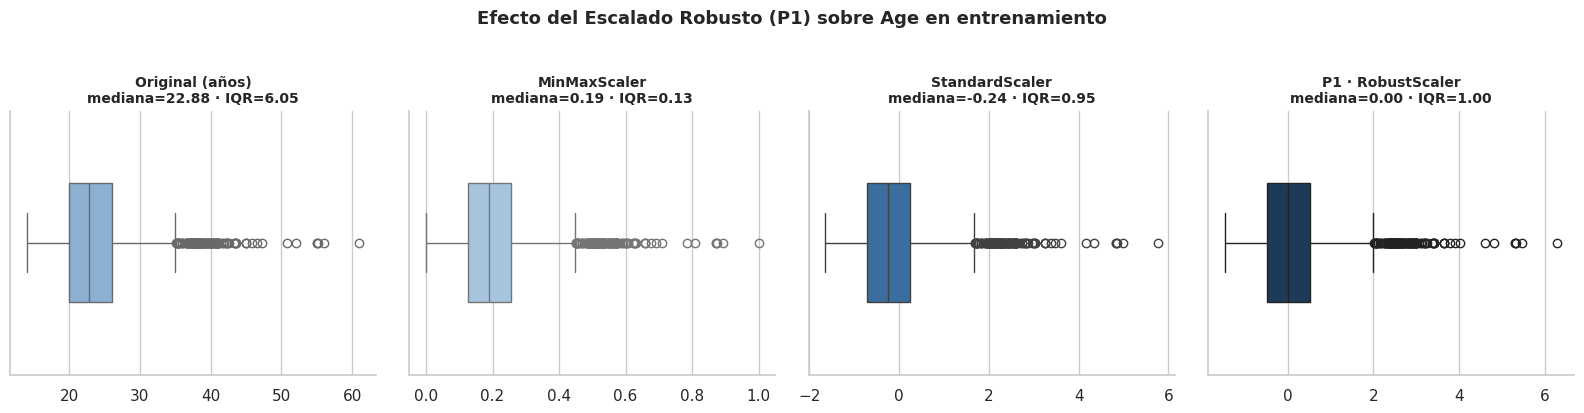

In [45]:
def crear_preprocesador_p1(X_tr=None):
    """Preprocesamiento P1: Escalado Robusto in-fold sobre el espacio base de 17 variables."""
    return Pipeline([
        ("scaler", RobustScaler()),
    ])


def crear_preprocesador_p2(X_tr):
    """Preprocesamiento P2: Ingeniería de Hábitos + Yeo-Johnson + StandardScaler (src/p2_habitos.py)."""
    return construir_p2(X_tr)


# Diccionario maestro de preprocesamientos disponibles para TODOS los modelos
preprocesadores = {
    "P1_RobustScaler": crear_preprocesador_p1,
    "P2_Habitos_YeoJohnson": crear_preprocesador_p2,
    # "P3_Robust_PCA95": crear_preprocesador_p3,   # <- Agregar aquí cuando esté listo P3
}

# --- Diagnóstico P1 (ajustado solo con X_train) ---
p1_demo = crear_preprocesador_p1(X_train)
X_train_p1 = pd.DataFrame(p1_demo.fit_transform(X_train), columns=X_train.columns, index=X_train.index)

cols_escala = ["Age", "FCVC", "NCP", "CH2O", "FAF", "TUE", "CAEC", "CALC"]
resumen_p1 = pd.DataFrame({
    "Antes · Mediana": X_train[cols_escala].median(),
    "Antes · IQR": X_train[cols_escala].quantile(0.75) - X_train[cols_escala].quantile(0.25),
    "Antes · [Min, Max]": [f"[{X_train[c].min():.1f}, {X_train[c].max():.1f}]" for c in cols_escala],
    "P1 · Mediana": X_train_p1[cols_escala].median().round(3),
    "P1 · IQR": (X_train_p1[cols_escala].quantile(0.75) - X_train_p1[cols_escala].quantile(0.25)).round(3),
    "P1 · [Min, Max]": [f"[{X_train_p1[c].min():.2f}, {X_train_p1[c].max():.2f}]" for c in cols_escala],
})
print("=== Diagnóstico P1 · Escalado Robusto (solo entrenamiento) ===")
display(resumen_p1)

# Comparación visual de escaladores sobre Age
age_col = X_train[["Age"]]
comparacion_age = pd.DataFrame({
    "Original (años)": age_col["Age"].values,
    "MinMaxScaler": MinMaxScaler().fit_transform(age_col).ravel(),
    "StandardScaler": StandardScaler().fit_transform(age_col).ravel(),
    "P1 · RobustScaler": RobustScaler().fit_transform(age_col).ravel(),
})

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (nombre, serie), color in zip(axes, comparacion_age.items(), ["#7fb1de", "#9ec5e8", "#2a6fb0", "#123b63"]):
    sns.boxplot(x=serie, ax=ax, color=color, width=0.45)
    iqr_val = np.percentile(serie, 75) - np.percentile(serie, 25)
    ax.set_title(f"{nombre}\nmediana={np.median(serie):.2f} · IQR={iqr_val:.2f}", fontsize=10, fontweight="bold")
    ax.set_xlabel("")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Efecto del Escalado Robusto (P1) sobre Age en entrenamiento", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

P2 -> entrada: 17 cols | salida: 21 cols | sin Weight/Height/IMC: OK
  Bloqueo anti-fuga verificado (Height): P2 no admite variables antropométricas (fuga de la clase): ['Height']
  Bloqueo anti-fuga verificado (IMC): P2 no admite variables antropométricas (fuga de la clase): ['IMC']
  Bloqueo anti-fuga verificado (Weight): P2 no admite variables antropométricas (fuga de la clase): ['Weight']


,Asimetría antes,Asimetría después,Lambda Yeo-Johnson,Reducción |asimetría|
CAEC,2.057,-0.156,-0.380,1.901
Age,1.466,0.087,-1.567,1.379
NCP,-1.085,-0.091,2.687,0.994
Balance_Act_Sed,1.041,0.071,-0.462,0.970
Hidratacion_Activa,1.005,0.005,-0.039,1.000
TUE,0.519,0.051,-0.237,0.468
FAF,0.452,-0.033,0.161,0.420
FCVC,-0.435,-0.169,2.111,0.266
Indice_Protector,0.299,-0.011,0.574,0.288
CALC,-0.248,-0.108,1.219,0.140


,rho de Spearman,p-valor
Balance_Act_Sed,-0.162,0.000
Hidratacion_Activa,-0.055,0.023
Riesgo_Gen_Cal,0.520,0.000
Indice_Protector,-0.025,0.313


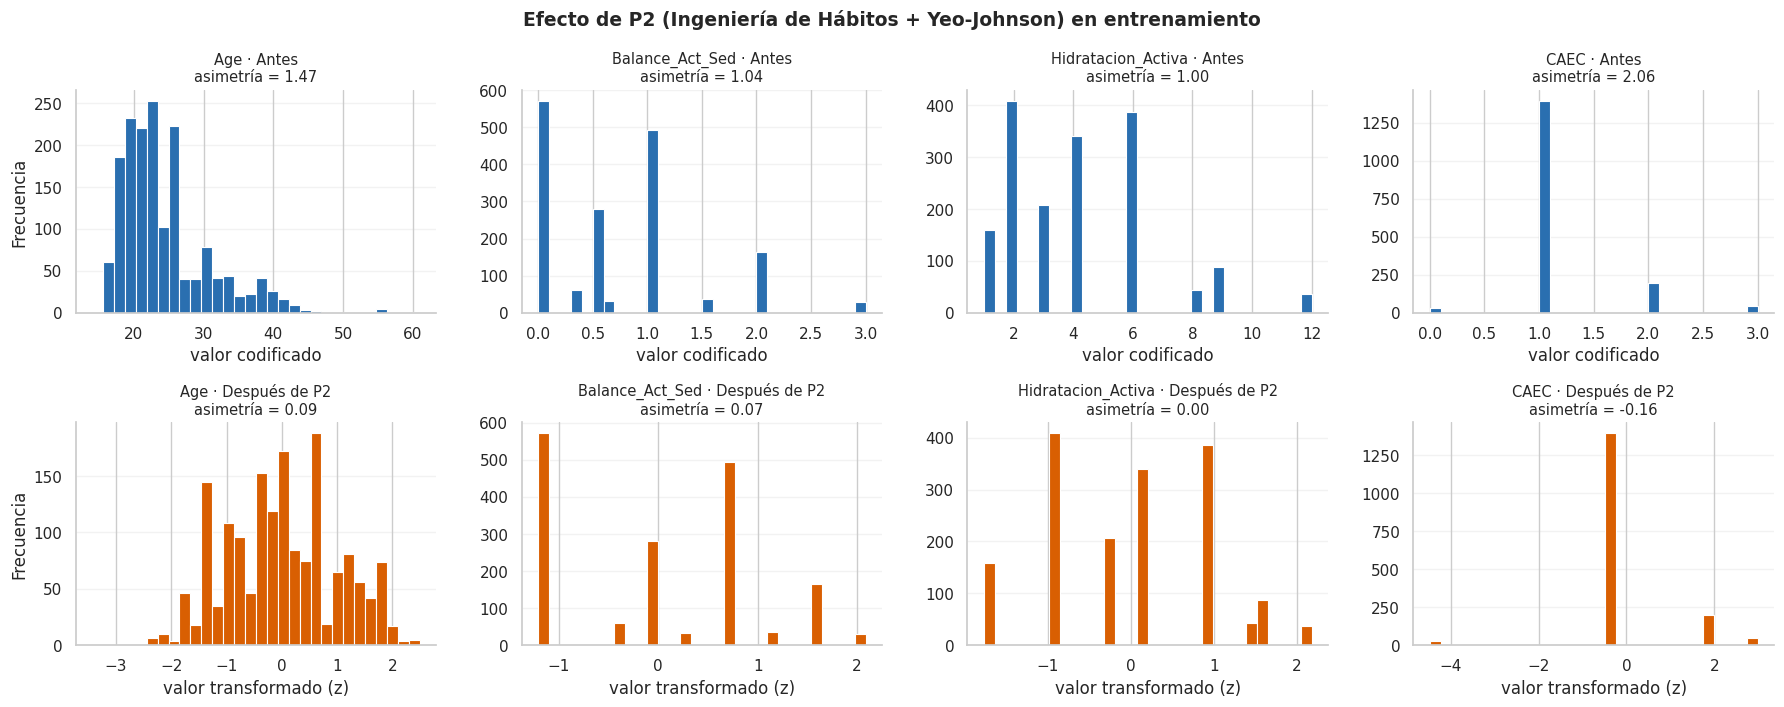

In [46]:
# --- Diagnóstico P2 (src/p2_habitos.py · ajustado solo con X_train) ---
p2_demo = crear_preprocesador_p2(X_train).set_output(transform="pandas")
p2_demo.fit(X_train)
X_train_p2 = p2_demo.transform(X_train)

# 1. Verificación anti-fuga de P2
prohibidas = set(FORBIDDEN_COLUMNS)
assert not prohibidas & set(X_train_p2.columns)
assert not prohibidas & set(p2_demo.get_feature_names_out())
print(f"P2 -> entrada: {X_train.shape[1]} cols | salida: {X_train_p2.shape[1]} cols | sin Weight/Height/IMC: OK")

for col in sorted(prohibidas):
    try:
        agregar_habitos(X_oper.loc[idx_train].drop(columns=list(prohibidas - {col})))
    except ValueError as e:
        print(f"  Bloqueo anti-fuga verificado ({col}): {e}")

# 2. Tabla de asimetría antes y después de Yeo-Johnson
crudo_train = agregar_habitos(X_train)
continuas_p2 = columnas_continuas(crudo_train)
yj_step = p2_demo.named_steps["transformacion"].named_transformers_["yeo_johnson"]

tabla_asimetria_p2 = pd.DataFrame({
    "Asimetría antes": [skew(crudo_train[c]) for c in continuas_p2],
    "Asimetría después": [skew(X_train_p2[c]) for c in continuas_p2],
    "Lambda Yeo-Johnson": yj_step.lambdas_,
}, index=continuas_p2)
tabla_asimetria_p2["Reducción |asimetría|"] = (
    tabla_asimetria_p2["Asimetría antes"].abs() - tabla_asimetria_p2["Asimetría después"].abs()
)
display(tabla_asimetria_p2.sort_values("Asimetría antes", key=abs, ascending=False))

# 3. Correlación de Spearman de las 4 variables nuevas con la clase en entrenamiento
spearman_p2 = pd.DataFrame(
    [spearmanr(crudo_train[c], y_train) for c in HABIT_FEATURES],
    index=HABIT_FEATURES, columns=["rho de Spearman", "p-valor"]
)
display(spearman_p2)

# 4. Gráfica antes vs. después de Yeo-Johnson en 4 variables clave
fijas = ["Age", "Balance_Act_Sed", "Hidratacion_Activa"]
cuarta = tabla_asimetria_p2.drop(index=fijas)["Asimetría antes"].abs().idxmax()
graficar_p2 = fijas + [cuarta]

fig, axes = plt.subplots(2, 4, figsize=(18, 7.2))
for j, col in enumerate(graficar_p2):
    for i, (serie, color, etapa) in enumerate([
        (crudo_train[col], AZUL, "Antes"),
        (X_train_p2[col], NARANJA, "Después de P2"),
    ]):
        ax = axes[i, j]
        ax.hist(serie, bins=30, color=color, edgecolor="white", linewidth=0.8)
        ax.set_title(f"{col} · {etapa}\nasimetría = {skew(serie):.2f}", fontsize=10.5)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.25)
    axes[0, j].set_xlabel("valor codificado")
    axes[1, j].set_xlabel("valor transformado (z)")
axes[0, 0].set_ylabel("Frecuencia")
axes[1, 0].set_ylabel("Frecuencia")
fig.suptitle("Efecto de P2 (Ingeniería de Hábitos + Yeo-Johnson) en entrenamiento", fontsize=13.5, fontweight="bold")
plt.tight_layout()
plt.show()

---
# Modelo M1: Clasificador Random Forest (`RandomForestClassifier`)

**Random Forest** es un ensamble por **Bagging** que entrena $T$ árboles de decisión independientes en paralelo sobre muestras *bootstrap* y selecciona un subconjunto aleatorio de $m$ variables por nodo (criterio de Gini).

### Complejidad computacional teórica (Big-O)
Sea $n$ el número de muestras de entrenamiento, $d$ las variables tras el preprocesamiento, $m \le d$ las evaluadas por nodo, $T$ los árboles y $h$ la profundidad máxima:

| Fase | Complejidad Big-O | Explicación |
| :--- | :---: | :--- |
| **Entrenamiento (tiempo)** | $\mathcal{O}(T \cdot m \cdot n \log_2 n)$ | Evaluación de cortes de Gini en $T$ árboles independientes (paralelizable). |
| **Inferencia por muestra** | $\mathcal{O}(T \cdot h)$ | Recorrido raíz → hoja en cada árbol y promedio de probabilidades. |
| **Memoria / Espacio** | $\mathcal{O}(T \cdot N_{\text{nodos}})$ | Almacena todos los nodos y distribuciones de clase por hoja. |

In [47]:
cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
etiquetas_cortas = [
    "Peso insuf.", "Normal", "Sobrepeso I", "Sobrepeso II",
    "Obesidad I", "Obesidad II", "Obesidad III",
]

param_dist_rf = {
    "clf__n_estimators": [150, 250, 350],
    "clf__max_depth": [6, 8, 10, 12, 16, None],
    "clf__min_samples_leaf": [1, 2, 4, 6],
    "clf__max_leaf_nodes": [None, 40, 80, 120],
    "clf__max_features": ["sqrt", "log2", 0.5],
}


def entrenar_evaluar_rf(nombre_prep, crear_prep, X_tr, y_tr, X_te, y_te, nombre_bench="Preventivo"):
    """Ajusta Random Forest con 5-Fold CV sobre un preprocesador y mide métricas + complejidad."""
    pipe = Pipeline([
        ("prep", crear_prep(X_tr)),
        ("clf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)),
    ])

    busqueda = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_dist_rf,
        n_iter=30,
        scoring="f1_macro",
        cv=cv_5,
        random_state=SEMILLA,
        n_jobs=-1,
        return_train_score=True,
    )
    busqueda.fit(X_tr, y_tr)

    # Medición limpia del tiempo de entrenamiento del mejor pipeline
    pipe_final = clone(busqueda.best_estimator_)
    t0 = time.perf_counter()
    pipe_final.fit(X_tr, y_tr)
    tiempo_fit_s = time.perf_counter() - t0

    # Medición limpia de latencia de inferencia sobre X_test
    t0 = time.perf_counter()
    y_pred_te = pipe_final.predict(X_te)
    latencia_total_ms = (time.perf_counter() - t0) * 1000
    y_pred_tr = pipe_final.predict(X_tr)

    # Tamaño en disco (.pkl) y estructura del bosque
    with tempfile.TemporaryDirectory() as carpeta:
        ruta_tmp = Path(carpeta) / "modelo.pkl"
        joblib.dump(pipe_final, ruta_tmp)
        tamano_kb = ruta_tmp.stat().st_size / 1024

    bosque = pipe_final.named_steps["clf"]
    total_nodos = int(sum(est.tree_.node_count for est in bosque.estimators_))
    prof_media = float(np.mean([est.tree_.max_depth for est in bosque.estimators_]))

    idx_best = busqueda.best_index_
    res_cv = busqueda.cv_results_
    cv_pliegues = np.array([res_cv[f"split{k}_test_score"][idx_best] for k in range(cv_5.get_n_splits())])
    train_acc = accuracy_score(y_tr, y_pred_tr)
    test_acc = accuracy_score(y_te, y_pred_te)

    registro = {
        "Modelo": "M1_RandomForest",
        "Preprocesamiento": nombre_prep,
        "Benchmark": nombre_bench,
        "CV F1-macro": f"{cv_pliegues.mean():.4f} ± {cv_pliegues.std():.4f}",
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Brecha Train-Test": round(train_acc - test_acc, 4),
        "Test F1-macro": round(f1_score(y_te, y_pred_te, average="macro"), 4),
        "Tiempo fit (s)": round(tiempo_fit_s, 4),
        "Latencia test (ms)": round(latencia_total_ms, 3),
        "ms / muestra": round(latencia_total_ms / len(X_te), 4),
        "Total nodos": total_nodos,
        "Prof. media": round(prof_media, 1),
        "Tamaño (.pkl KB)": round(tamano_kb, 1),
        "Mejores hiperparámetros": busqueda.best_params_,
    }
    extra = {"cv_media": float(cv_pliegues.mean()), "cv_pliegues": cv_pliegues}
    return pipe_final, registro, extra


modelos_rf, resultados_rf, extras_rf = {}, [], {}
for nombre_p, crear_prep in preprocesadores.items():
    t0 = time.perf_counter()
    modelo_rf, fila_rf, extra_rf = entrenar_evaluar_rf(
        nombre_p, crear_prep, X_train, y_train, X_test, y_test, nombre_bench="Preventivo"
    )
    modelos_rf[nombre_p], extras_rf[nombre_p] = modelo_rf, extra_rf
    resultados_rf.append(fila_rf)
    print(f"M1 Random Forest · {nombre_p}: búsqueda terminada en {time.perf_counter() - t0:,.1f} s")
    print("  Mejores hiperparámetros:", fila_rf["Mejores hiperparámetros"])

MEJOR_PREP_RF = max(extras_rf, key=lambda k: extras_rf[k]["cv_media"])
print(f"\nMejor preprocesamiento para M1 según CV: {MEJOR_PREP_RF}")
tabla_rf = pd.DataFrame(resultados_rf)
display(tabla_rf.drop(columns=["Mejores hiperparámetros"]))

M1 Random Forest · P1_RobustScaler: búsqueda terminada en 33.8 s
  Mejores hiperparámetros: {'clf__n_estimators': 350, 'clf__min_samples_leaf': 2, 'clf__max_leaf_nodes': 120, 'clf__max_features': 'sqrt', 'clf__max_depth': None}
M1 Random Forest · P2_Habitos_YeoJohnson: búsqueda terminada en 33.5 s
  Mejores hiperparámetros: {'clf__n_estimators': 250, 'clf__min_samples_leaf': 2, 'clf__max_leaf_nodes': 120, 'clf__max_features': 0.5, 'clf__max_depth': 10}

Mejor preprocesamiento para M1 según CV: P1_RobustScaler


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Total nodos,Prof. media,Tamaño (.pkl KB)
0,M1_RandomForest,P1_RobustScaler,Preventivo,0.7749 ± 0.0143,0.889,0.789,0.100,0.782,0.927,136.303,0.326,83650,14.400,"9,955.700"
1,M1_RandomForest,P2_Habitos_YeoJohnson,Preventivo,0.7638 ± 0.0209,0.891,0.766,0.125,0.755,0.708,97.081,0.232,59750,10.000,"7,122.700"


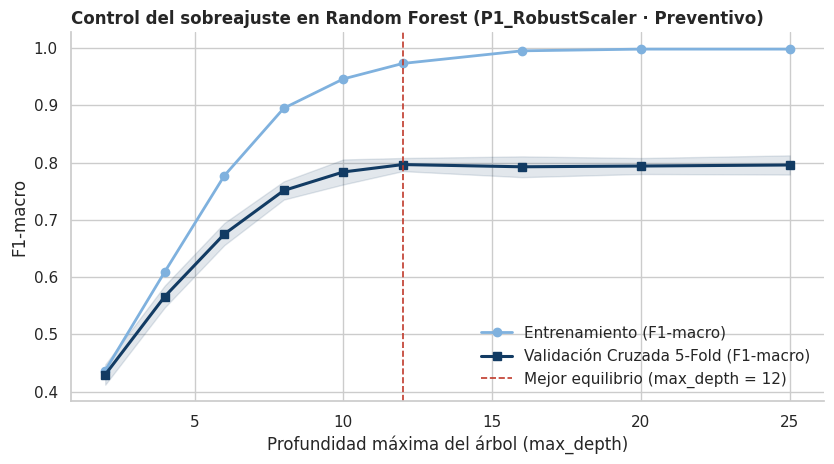

In [48]:
# Curva de validación según max_depth sobre el mejor preprocesamiento de M1
profundidades = [2, 4, 6, 8, 10, 12, 16, 20, 25]
pipe_curva_rf = Pipeline([
    ("prep", preprocesadores[MEJOR_PREP_RF](X_train)),
    ("clf", RandomForestClassifier(n_estimators=250, random_state=SEMILLA, n_jobs=-1)),
])

tr_scores, val_scores = validation_curve(
    pipe_curva_rf, X_train, y_train,
    param_name="clf__max_depth",
    param_range=profundidades,
    cv=cv_5,
    scoring="f1_macro",
    n_jobs=-1,
)

tr_mean, val_mean, val_std = tr_scores.mean(axis=1), val_scores.mean(axis=1), val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(profundidades, tr_mean, marker="o", color="#7fb1de", lw=2, label="Entrenamiento (F1-macro)")
ax.plot(profundidades, val_mean, marker="s", color="#123b63", lw=2.2, label="Validación Cruzada 5-Fold (F1-macro)")
ax.fill_between(profundidades, val_mean - val_std, val_mean + val_std, color="#123b63", alpha=0.12)

mejor_d = profundidades[int(np.argmax(val_mean))]
ax.axvline(mejor_d, color="#c0392b", ls="--", lw=1.2, label=f"Mejor equilibrio (max_depth = {mejor_d})")
ax.set_xlabel("Profundidad máxima del árbol (max_depth)")
ax.set_ylabel("F1-macro")
ax.set_title(f"Control del sobreajuste en Random Forest ({MEJOR_PREP_RF} · Preventivo)", fontweight="bold", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [49]:
# Controles científicos de M1: 1) Sin Gender (mejor preprocesamiento) · 2) Operativo (con P1)
modelo_rf_sin_gender, res_rf_sin_gender, _ = entrenar_evaluar_rf(
    MEJOR_PREP_RF, preprocesadores[MEJOR_PREP_RF],
    X_train.drop(columns=["Gender"]), y_train, X_test.drop(columns=["Gender"]), y_test,
    nombre_bench="Preventivo (sin Gender)",
)

modelo_rf_oper, res_rf_oper, _ = entrenar_evaluar_rf(
    "P1_RobustScaler", crear_preprocesador_p1,
    X_train_oper, y_train, X_test_oper, y_test,
    nombre_bench="Operativo (con Peso/Altura/IMC)",
)

fila_mejor_rf = next(f for f in resultados_rf if f["Preprocesamiento"] == MEJOR_PREP_RF)
comparacion_controles_rf = pd.DataFrame([fila_mejor_rf, res_rf_sin_gender, res_rf_oper])
display(comparacion_controles_rf.drop(columns=["Mejores hiperparámetros"]))

,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Total nodos,Prof. media,Tamaño (.pkl KB)
0,M1_RandomForest,P1_RobustScaler,Preventivo,0.7749 ± 0.0143,0.889,0.789,0.100,0.782,0.927,136.303,0.326,83650,14.400,"9,955.700"
1,M1_RandomForest,P1_RobustScaler,Preventivo (sin Gender),0.7375 ± 0.0076,0.874,0.744,0.130,0.735,0.650,89.034,0.213,59750,14.100,"7,115.800"
2,M1_RandomForest,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9851 ± 0.0042,0.999,0.986,0.014,0.985,0.914,118.973,0.285,75894,13.300,"9,046.900"


=== Reporte por clase · M1 Random Forest + P1_RobustScaler (Preventivo) ===

              precision    recall  f1-score   support

 Peso insuf.      0.807     0.868     0.836        53
      Normal      0.640     0.561     0.598        57
 Sobrepeso I      0.741     0.727     0.734        55
Sobrepeso II      0.760     0.655     0.704        58
  Obesidad I      0.800     0.743     0.770        70
 Obesidad II      0.766     0.983     0.861        60
Obesidad III      0.969     0.969     0.969        65

    accuracy                          0.789       418
   macro avg      0.783     0.787     0.782       418
weighted avg      0.787     0.789     0.785       418



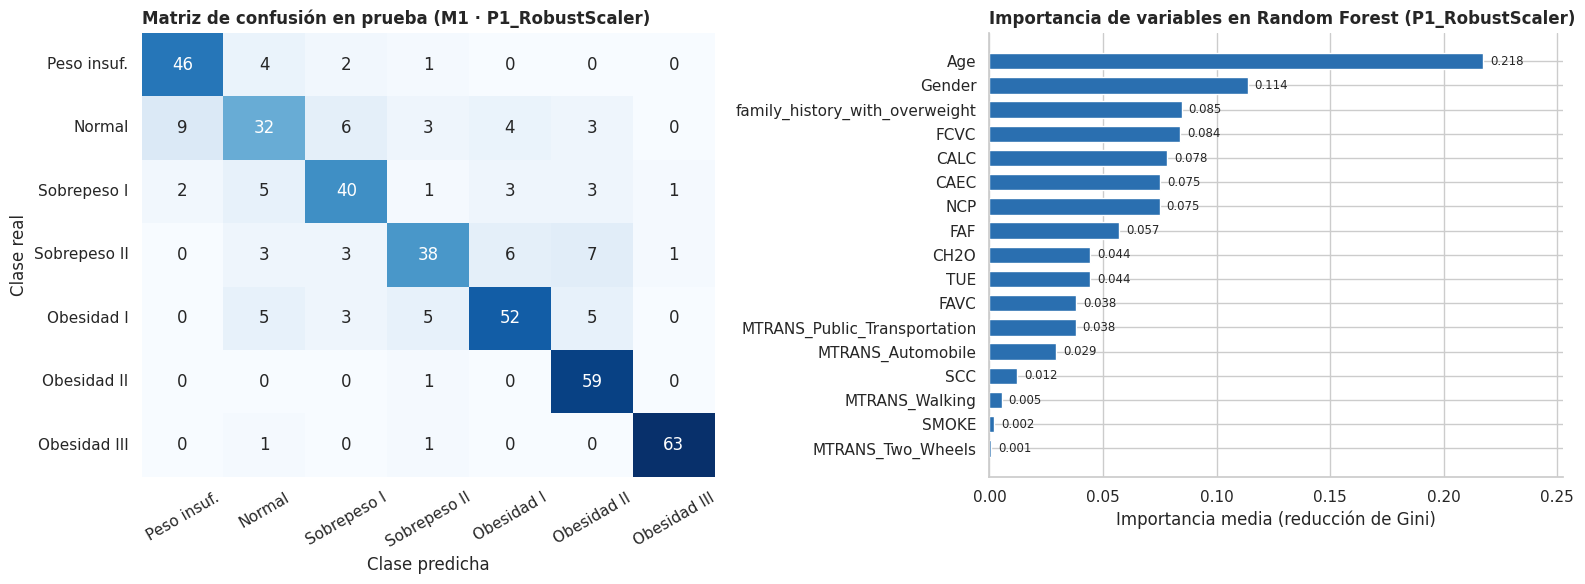

In [50]:
pipe_mejor_rf = modelos_rf[MEJOR_PREP_RF]
y_pred_test_rf = pipe_mejor_rf.predict(X_test)

print(f"=== Reporte por clase · M1 Random Forest + {MEJOR_PREP_RF} (Preventivo) ===\n")
print(classification_report(y_test, y_pred_test_rf, target_names=etiquetas_cortas, digits=3))

# Nombres exactos de salida del preprocesador (funciona igual para P1 [17 cols] y P2 [21 cols])
prep_rf = pipe_mejor_rf.named_steps["prep"]
nombres_vars_rf = (
    list(prep_rf.get_feature_names_out())
    if hasattr(prep_rf, "get_feature_names_out")
    else list(X_train.columns)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred_test_rf), annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=etiquetas_cortas, yticklabels=etiquetas_cortas, ax=axes[0]
)
axes[0].set_title(f"Matriz de confusión en prueba (M1 · {MEJOR_PREP_RF})", fontweight="bold", loc="left")
axes[0].set_xlabel("Clase predicha")
axes[0].set_ylabel("Clase real")
axes[0].tick_params(axis="x", rotation=30)
axes[0].tick_params(axis="y", rotation=0)

imp_rf = pd.Series(
    pipe_mejor_rf.named_steps["clf"].feature_importances_,
    index=nombres_vars_rf,
).sort_values()

axes[1].barh(imp_rf.index, imp_rf.values, color="#2a6fb0", height=0.68)
for idx_y, val in enumerate(imp_rf.values):
    axes[1].text(val + 0.003, idx_y, f"{val:.3f}", va="center", fontsize=8.5)
axes[1].set_xlim(0, imp_rf.max() * 1.16)
axes[1].set_xlabel("Importancia media (reducción de Gini)")
axes[1].set_title(f"Importancia de variables en Random Forest ({MEJOR_PREP_RF})", fontweight="bold", loc="left")
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

---
# Modelo M3: Perceptrón Multicapa (`MLPClassifier`)

*(Integrado desde `m3-mlp.ipynb` — Juan David Velasco, usando el mismo protocolo de validación y hardware que M1).*

El MLP es una red densa (*feed-forward*). Cada capa oculta calcula:

$$h^{(l)} = \text{ReLU}\left(W^{(l)} h^{(l-1)} + b^{(l)}\right), \qquad \text{ReLU}(z) = \max(0, z)$$

y la capa de salida aplica *softmax* sobre las 7 clases. Los pesos se optimizan con **Adam** minimizando entropía cruzada + penalización $L_2$ (`alpha`) y *early stopping* (10 % de validación interna, paciencia de 30 épocas).

### Complejidad computacional teórica (Big-O)
Sea $n$ las muestras de entrenamiento, $E$ las épocas ejecutadas y $W = \sum_{l=1}^{L+1} (n_{l-1} + 1) n_l$ los parámetros totales:

| Fase | Complejidad | Explicación |
| :--- | :---: | :--- |
| **Entrenamiento (tiempo)** | $\mathcal{O}(E \cdot n \cdot W)$ | Cada época recorre las $n$ muestras con propagación hacia adelante y atrás. |
| **Inferencia por muestra** | $\mathcal{O}(W)$ | Solo multiplicaciones de matrices de pesos. |
| **Memoria / Espacio** | $\mathcal{O}(W)$ | Pesos, sesgos y momentos del optimizador Adam. |

In [51]:
param_dist_mlp = {
    "clf__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64), (256, 128), (128, 64, 32)],
    "clf__alpha": [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 0.5],
    "clf__learning_rate_init": [1e-3, 3e-3, 1e-2, 3e-2],
    "clf__batch_size": [16, 32, 64, 128],
}


def crear_mlp(semilla=SEMILLA):
    return MLPClassifier(
        activation="relu", solver="adam",
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
        max_iter=1000, random_state=semilla,
    )


def contar_parametros(mlp):
    return int(sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_))


def entrenar_evaluar_mlp(nombre_prep, crear_prep, X_tr, y_tr, X_te, y_te, nombre_bench="Preventivo"):
    pipe = Pipeline([("prep", crear_prep(X_tr)), ("clf", crear_mlp())])

    busqueda = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_dist_mlp,
        n_iter=30,
        scoring="f1_macro",
        cv=cv_5,
        random_state=SEMILLA,
        n_jobs=-1,
        return_train_score=True,
    )
    busqueda.fit(X_tr, y_tr)

    pipe_final = clone(busqueda.best_estimator_)
    t0 = time.perf_counter()
    pipe_final.fit(X_tr, y_tr)
    tiempo_fit_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    y_pred_te = pipe_final.predict(X_te)
    latencia_total_ms = (time.perf_counter() - t0) * 1000
    y_pred_tr = pipe_final.predict(X_tr)

    with tempfile.TemporaryDirectory() as carpeta:
        ruta_tmp = Path(carpeta) / "modelo.pkl"
        joblib.dump(pipe_final, ruta_tmp)
        tamano_kb = ruta_tmp.stat().st_size / 1024

    mlp = pipe_final.named_steps["clf"]
    i = busqueda.best_index_
    res = busqueda.cv_results_
    cv_pliegues = np.array([res[f"split{k}_test_score"][i] for k in range(cv_5.get_n_splits())])
    train_acc = accuracy_score(y_tr, y_pred_tr)
    test_acc = accuracy_score(y_te, y_pred_te)

    registro = {
        "Modelo": "M3_MLP",
        "Preprocesamiento": nombre_prep,
        "Benchmark": nombre_bench,
        "CV F1-macro": f"{cv_pliegues.mean():.4f} ± {cv_pliegues.std():.4f}",
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Brecha Train-Test": round(train_acc - test_acc, 4),
        "Test F1-macro": round(f1_score(y_te, y_pred_te, average="macro"), 4),
        "Tiempo fit (s)": round(tiempo_fit_s, 4),
        "Latencia test (ms)": round(latencia_total_ms, 3),
        "ms / muestra": round(latencia_total_ms / len(X_te), 4),
        "Capas ocultas": str(mlp.hidden_layer_sizes),
        "Parámetros (W)": contar_parametros(mlp),
        "Épocas": int(mlp.n_iter_),
        "Tamaño (.pkl KB)": round(tamano_kb, 1),
        "Mejores hiperparámetros": busqueda.best_params_,
    }
    extra = {"cv_media": float(cv_pliegues.mean()), "cv_pliegues": cv_pliegues}
    return pipe_final, registro, extra


modelos_mlp, resultados_mlp, extras_mlp = {}, [], {}
for nombre_p, crear_prep in preprocesadores.items():
    t0 = time.perf_counter()
    modelo_m, fila_m, extra_m = entrenar_evaluar_mlp(
        nombre_p, crear_prep, X_train, y_train, X_test, y_test, nombre_bench="Preventivo"
    )
    modelos_mlp[nombre_p], extras_mlp[nombre_p] = modelo_m, extra_m
    resultados_mlp.append(fila_m)
    print(f"M3 MLP · {nombre_p}: búsqueda terminada en {time.perf_counter() - t0:,.1f} s")
    print("  Mejores hiperparámetros:", fila_m["Mejores hiperparámetros"])

MEJOR_PREP_MLP = max(extras_mlp, key=lambda k: extras_mlp[k]["cv_media"])
print(f"\nMejor preprocesamiento para M3 según CV: {MEJOR_PREP_MLP}")
tabla_mlp = pd.DataFrame(resultados_mlp)
display(tabla_mlp.drop(columns=["Mejores hiperparámetros"]))

M3 MLP · P1_RobustScaler: búsqueda terminada en 89.7 s
  Mejores hiperparámetros: {'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (256, 128), 'clf__batch_size': 32, 'clf__alpha': 0.001}
M3 MLP · P2_Habitos_YeoJohnson: búsqueda terminada en 88.5 s
  Mejores hiperparámetros: {'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (256, 128), 'clf__batch_size': 32, 'clf__alpha': 0.001}

Mejor preprocesamiento para M3 según CV: P2_Habitos_YeoJohnson


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Capas ocultas,Parámetros (W),Épocas,Tamaño (.pkl KB)
0,M3_MLP,P1_RobustScaler,Preventivo,0.7421 ± 0.0134,0.927,0.766,0.161,0.756,9.845,4.674,0.011,"(256, 128)",38407,72,911.100
1,M3_MLP,P2_Habitos_YeoJohnson,Preventivo,0.7491 ± 0.0027,0.860,0.756,0.104,0.752,3.793,12.937,0.031,"(256, 128)",39431,44,937.300


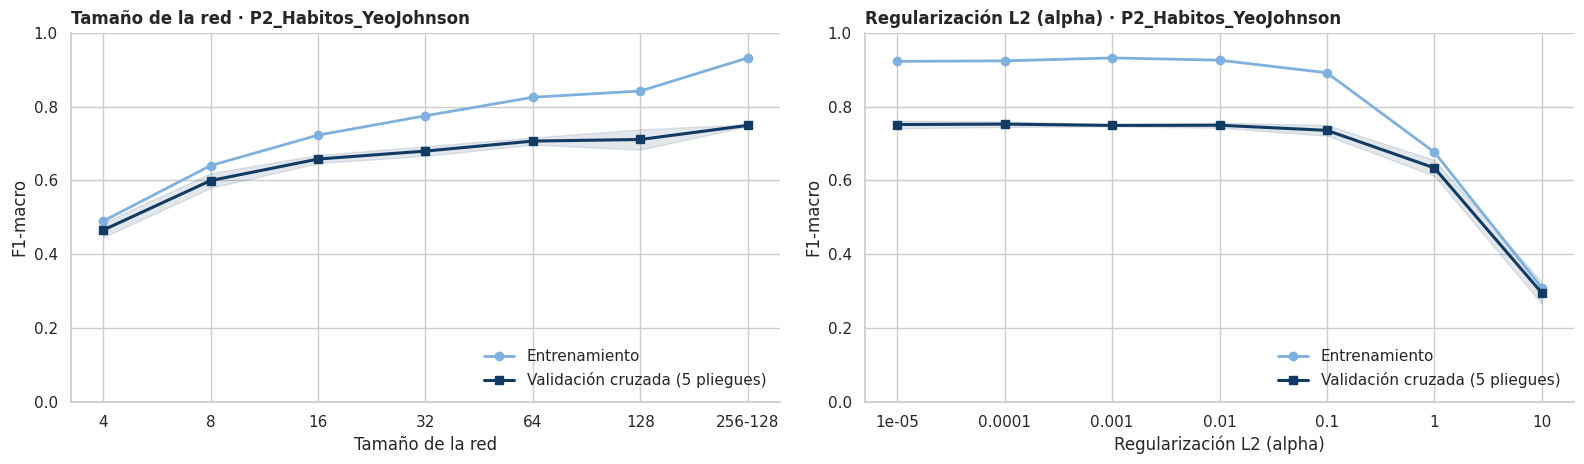

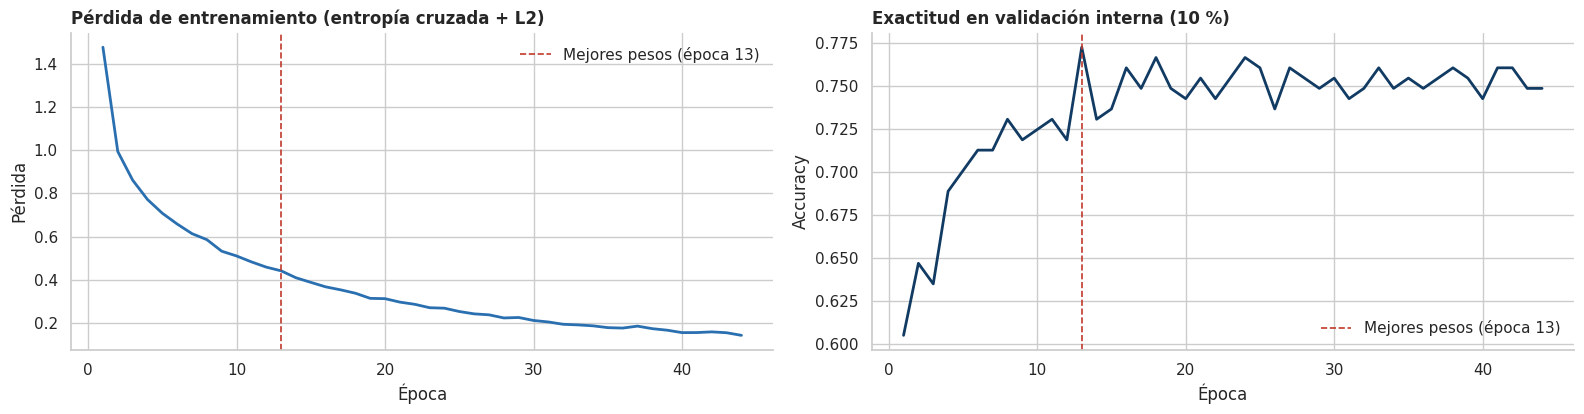

In [52]:
# Control del sobreajuste en M3: tamaño de red, regularización L2 (alpha) y curva por épocas
pipe_mejor_mlp = modelos_mlp[MEJOR_PREP_MLP]
arquitecturas = [(4,), (8,), (16,), (32,), (64,), (128,), (256, 128)]
alphas = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0]


def curva_mlp(parametro, valores):
    rango = np.empty(len(valores), dtype=object)
    rango[:] = valores
    tr, val = validation_curve(
        clone(pipe_mejor_mlp), X_train, y_train, param_name=parametro, param_range=rango,
        cv=cv_5, scoring="f1_macro", n_jobs=-1,
    )
    return tr.mean(axis=1), val.mean(axis=1), val.std(axis=1)


fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, (parametro, valores, titulo, etiquetas_x) in zip(axes, [
    ("clf__hidden_layer_sizes", arquitecturas, "Tamaño de la red", ["-".join(map(str, a)) for a in arquitecturas]),
    ("clf__alpha", alphas, "Regularización L2 (alpha)", [f"{a:g}" for a in alphas]),
]):
    tr_m, val_m, val_s = curva_mlp(parametro, valores)
    x = np.arange(len(valores))
    ax.plot(x, tr_m, marker="o", color="#7fb1de", lw=2, label="Entrenamiento")
    ax.plot(x, val_m, marker="s", color="#123b63", lw=2.2, label="Validación cruzada (5 pliegues)")
    ax.fill_between(x, val_m - val_s, val_m + val_s, color="#123b63", alpha=0.12)
    ax.set_xticks(x, etiquetas_x)
    ax.set_xlabel(titulo)
    ax.set_ylabel("F1-macro")
    ax.set_ylim(0, 1)
    ax.set_title(f"{titulo} · {MEJOR_PREP_MLP}", fontweight="bold", loc="left")
    ax.legend(frameon=False, loc="lower right")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Curvas por época (early stopping)
mlp_est = pipe_mejor_mlp.named_steps["clf"]
epocas = np.arange(1, mlp_est.n_iter_ + 1)
mejor_epoca = int(np.argmax(mlp_est.validation_scores_)) + 1

fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
axes[0].plot(epocas, mlp_est.loss_curve_, color="#2a6fb0", lw=2)
axes[0].set_title("Pérdida de entrenamiento (entropía cruzada + L2)", fontweight="bold", loc="left")
axes[0].set_ylabel("Pérdida")
axes[1].plot(epocas, mlp_est.validation_scores_, color="#123b63", lw=2)
axes[1].set_title("Exactitud en validación interna (10 %)", fontweight="bold", loc="left")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.axvline(mejor_epoca, color="#c0392b", ls="--", lw=1.2, label=f"Mejores pesos (época {mejor_epoca})")
    ax.set_xlabel("Época")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Capas ocultas,Parámetros (W),Épocas,Tamaño (.pkl KB)
0,M3_MLP,P2_Habitos_YeoJohnson,Preventivo,0.7491 ± 0.0027,0.860,0.756,0.104,0.752,3.793,12.937,0.031,"(256, 128)",39431,44,937.300
1,M3_MLP,P2_Habitos_YeoJohnson,Preventivo (sin Gender),0.7120 ± 0.0117,0.785,0.723,0.062,0.715,7.070,13.739,0.033,"(256, 128)",39175,39,931.100
2,M3_MLP,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9642 ± 0.0068,0.995,0.959,0.035,0.959,3.558,7.053,0.017,"(128, 64, 32)",13255,49,321.300



=== Reporte por clase · M3 MLP + P2_Habitos_YeoJohnson (Preventivo) ===

              precision    recall  f1-score   support

 Peso insuf.      0.900     0.849     0.874        53
      Normal      0.596     0.596     0.596        57
 Sobrepeso I      0.627     0.673     0.649        55
Sobrepeso II      0.660     0.569     0.611        58
  Obesidad I      0.716     0.686     0.701        70
 Obesidad II      0.789     0.933     0.855        60
Obesidad III      0.984     0.969     0.977        65

    accuracy                          0.756       418
   macro avg      0.753     0.754     0.752       418
weighted avg      0.756     0.756     0.754       418



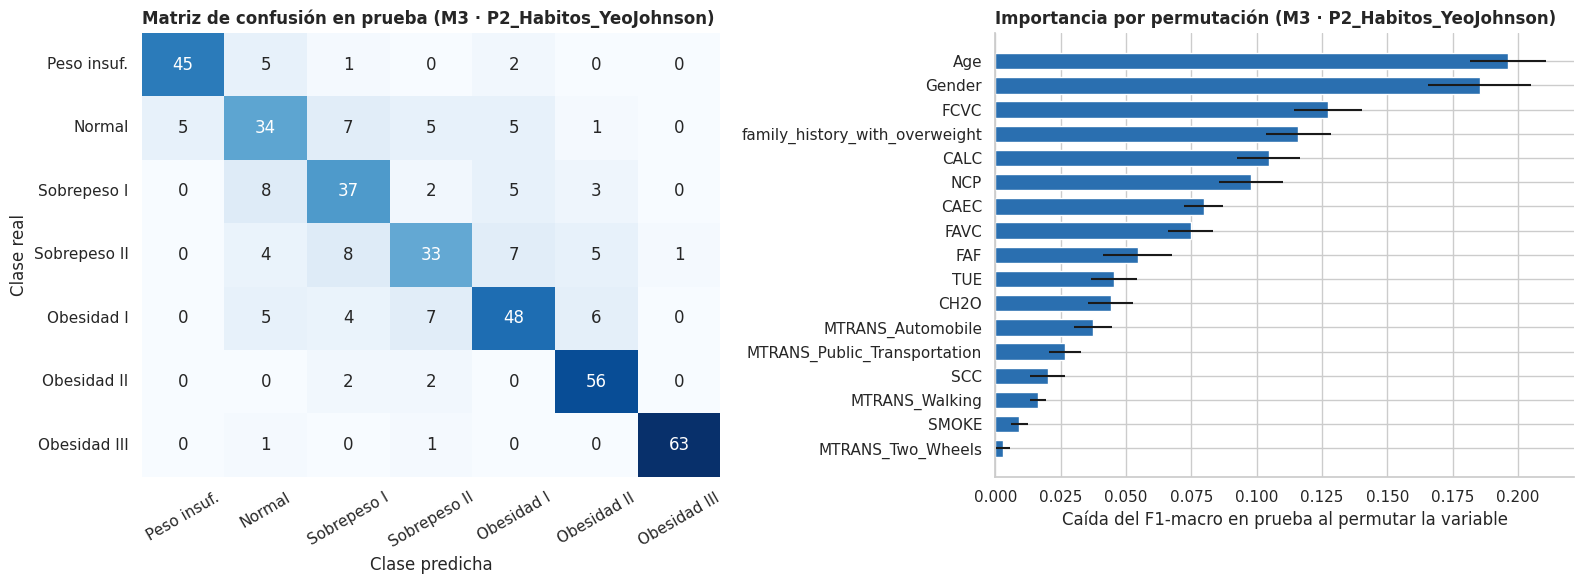

In [53]:
# Controles científicos de M3: sin Gender y benchmark operativo
modelo_mlp_sin_gender, res_mlp_sin_gender, _ = entrenar_evaluar_mlp(
    MEJOR_PREP_MLP, preprocesadores[MEJOR_PREP_MLP],
    X_train.drop(columns=["Gender"]), y_train, X_test.drop(columns=["Gender"]), y_test,
    nombre_bench="Preventivo (sin Gender)",
)

modelo_mlp_oper, res_mlp_oper, _ = entrenar_evaluar_mlp(
    "P1_RobustScaler", crear_preprocesador_p1,
    X_train_oper, y_train, X_test_oper, y_test,
    nombre_bench="Operativo (con Peso/Altura/IMC)",
)

fila_mejor_mlp = next(f for f in resultados_mlp if f["Preprocesamiento"] == MEJOR_PREP_MLP)
comparacion_controles_mlp = pd.DataFrame([fila_mejor_mlp, res_mlp_sin_gender, res_mlp_oper])
display(comparacion_controles_mlp.drop(columns=["Mejores hiperparámetros"]))

# Evaluación en prueba: reporte por clase, matriz de confusión e importancia por permutación
y_pred_test_mlp = pipe_mejor_mlp.predict(X_test)
print(f"\n=== Reporte por clase · M3 MLP + {MEJOR_PREP_MLP} (Preventivo) ===\n")
print(classification_report(y_test, y_pred_test_mlp, target_names=etiquetas_cortas, digits=3))

perm_mlp = permutation_importance(
    pipe_mejor_mlp, X_test, y_test, scoring="f1_macro", n_repeats=20, random_state=SEMILLA, n_jobs=-1
)
imp_mlp = pd.DataFrame(
    {"media": perm_mlp.importances_mean, "desv": perm_mlp.importances_std},
    index=X_test.columns,
).sort_values("media")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred_test_mlp), annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=etiquetas_cortas, yticklabels=etiquetas_cortas, ax=axes[0]
)
axes[0].set_title(f"Matriz de confusión en prueba (M3 · {MEJOR_PREP_MLP})", fontweight="bold", loc="left")
axes[0].set_xlabel("Clase predicha")
axes[0].set_ylabel("Clase real")
axes[0].tick_params(axis="x", rotation=30)
axes[0].tick_params(axis="y", rotation=0)

axes[1].barh(imp_mlp.index, imp_mlp["media"], xerr=imp_mlp["desv"], color="#2a6fb0", height=0.68)
axes[1].set_xlabel("Caída del F1-macro en prueba al permutar la variable")
axes[1].set_title(f"Importancia por permutación (M3 · {MEJOR_PREP_MLP})", fontweight="bold", loc="left")
axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [54]:
# Estabilidad de M3 ante 10 semillas aleatorias
filas_semillas = []
for semilla in [SEMILLA] + list(range(9)):
    p = clone(pipe_mejor_mlp).set_params(clf__random_state=semilla).fit(X_train, y_train)
    pred = p.predict(X_test)
    filas_semillas.append({
        "semilla": semilla,
        "Test F1-macro": f1_score(y_test, pred, average="macro"),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Épocas": p.named_steps["clf"].n_iter_,
    })
semillas_df = pd.DataFrame(filas_semillas).set_index("semilla")
display(semillas_df.agg(["mean", "std", "min", "max"]))

,Test F1-macro,Test Accuracy,Épocas
mean,0.759,0.765,64.200
std,0.012,0.011,19.395
min,0.744,0.751,44.000
max,0.777,0.782,108.000


---
# Consolidado de la Matriz Experimental y Análisis de Complejidad

Comparación directa en el **mismo entorno de ejecución** entre los modelos y preprocesamientos ya integrados (`M1 · Random Forest` y `M3 · MLP` sobre `P1` y `P2`).

> **Espacio listo para completar la matriz $3 \times 3$:** cuando estén listos **`P3` (`PCA 95%`)** y **`M2` (`XGBoost`)**, basta agregar `P3` al diccionario `preprocesadores` y añadir la sección de `M2` antes de esta tabla consolidada.

=== Tabla Consolidada · Benchmark Preventivo (misma máquina y mismo split) ===


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Tamaño (.pkl KB)
0,M1_RandomForest,P1_RobustScaler,Preventivo,0.7749 ± 0.0143,0.889,0.789,0.100,0.782,0.927,136.303,0.326,"9,955.700"
2,M3_MLP,P1_RobustScaler,Preventivo,0.7421 ± 0.0134,0.927,0.766,0.161,0.756,9.845,4.674,0.011,911.100
1,M1_RandomForest,P2_Habitos_YeoJohnson,Preventivo,0.7638 ± 0.0209,0.891,0.766,0.125,0.755,0.708,97.081,0.232,"7,122.700"
3,M3_MLP,P2_Habitos_YeoJohnson,Preventivo,0.7491 ± 0.0027,0.860,0.756,0.104,0.752,3.793,12.937,0.031,937.300



=== Tabla de Controles · Sin Gender y Operativo (fuga de IMC) ===


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Tamaño (.pkl KB)
0,M1_RandomForest,P1_RobustScaler,Preventivo (sin Gender),0.7375 ± 0.0076,0.874,0.744,0.130,0.735,0.650,89.034,0.213,"7,115.800"
1,M1_RandomForest,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9851 ± 0.0042,0.999,0.986,0.014,0.985,0.914,118.973,0.285,"9,046.900"
2,M3_MLP,P2_Habitos_YeoJohnson,Preventivo (sin Gender),0.7120 ± 0.0117,0.785,0.723,0.062,0.715,7.070,13.739,0.033,931.100
3,M3_MLP,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9642 ± 0.0068,0.995,0.959,0.035,0.959,3.558,7.053,0.017,321.300


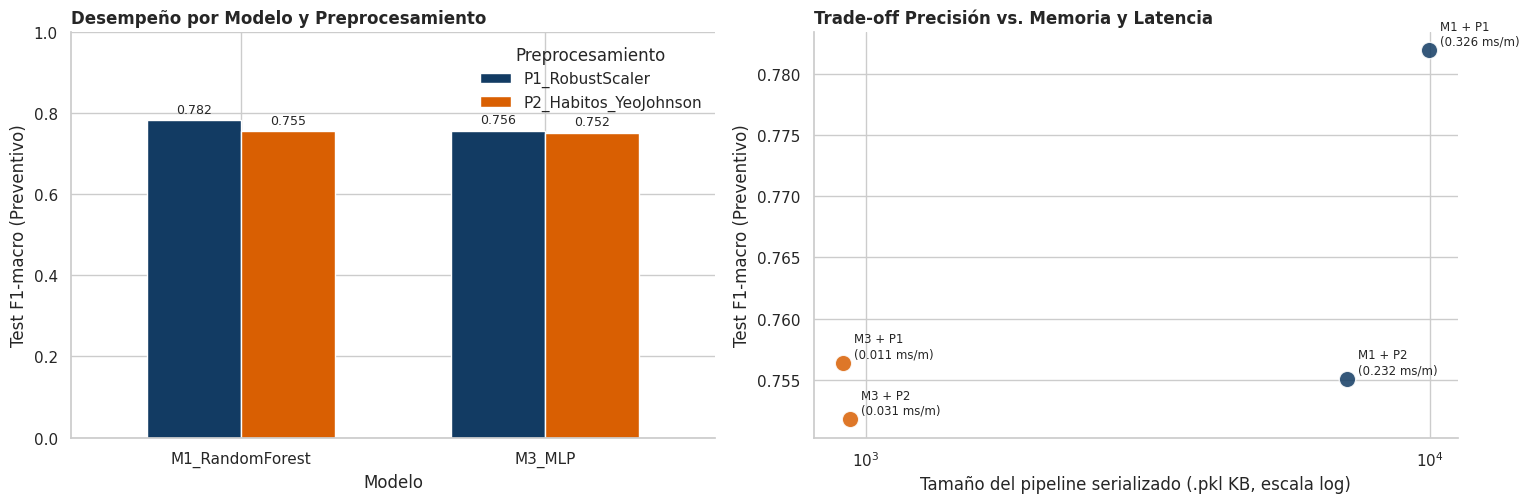

In [55]:
COLS_CONSOLIDADAS = [
    "Modelo", "Preprocesamiento", "Benchmark", "CV F1-macro",
    "Train Accuracy", "Test Accuracy", "Brecha Train-Test", "Test F1-macro",
    "Tiempo fit (s)", "Latencia test (ms)", "ms / muestra", "Tamaño (.pkl KB)",
]

tabla_matriz_prev = pd.concat([
    tabla_rf[COLS_CONSOLIDADAS],
    tabla_mlp[COLS_CONSOLIDADAS],
    # tabla_xgb[COLS_CONSOLIDADAS],   # <- Agregar aquí cuando esté listo M2
], ignore_index=True)

tabla_matriz_controles = pd.concat([
    comparacion_controles_rf.iloc[1:][COLS_CONSOLIDADAS],
    comparacion_controles_mlp.iloc[1:][COLS_CONSOLIDADAS],
], ignore_index=True)

tabla_matriz_completa = pd.concat([tabla_matriz_prev, tabla_matriz_controles], ignore_index=True)

print("=== Tabla Consolidada · Benchmark Preventivo (misma máquina y mismo split) ===")
display(tabla_matriz_prev.sort_values("Test F1-macro", ascending=False))

print("\n=== Tabla de Controles · Sin Gender y Operativo (fuga de IMC) ===")
display(tabla_matriz_controles)

# Gráfica comparativa de rendimiento vs. complejidad empírica
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))

# Panel 1: Test F1-macro agrupado por Modelo x Preprocesamiento
piv_f1 = tabla_matriz_prev.pivot(index="Modelo", columns="Preprocesamiento", values="Test F1-macro")
piv_f1.plot(kind="bar", ax=axes[0], color=["#123b63", "#d95f02"], width=0.62, edgecolor="white")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=9, padding=3)
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel("Test F1-macro (Preventivo)")
axes[0].set_title("Desempeño por Modelo y Preprocesamiento", fontweight="bold", loc="left")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Preprocesamiento", frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

# Panel 2: Trade-off Complejidad (Tamaño .pkl vs. Test F1-macro, anotando latencia)
for _, r in tabla_matriz_prev.iterrows():
    etq = f"{r['Modelo'].split('_')[0]} + {r['Preprocesamiento'].split('_')[0]}"
    color = "#123b63" if "RandomForest" in r["Modelo"] else "#d95f02"
    axes[1].scatter(r["Tamaño (.pkl KB)"], r["Test F1-macro"], s=140, color=color, alpha=0.85, edgecolors="white")
    axes[1].annotate(
        f"{etq}\n({r['ms / muestra']:.3f} ms/m)",
        (r["Tamaño (.pkl KB)"], r["Test F1-macro"]),
        textcoords="offset points", xytext=(8, 4), fontsize=8.5,
    )
axes[1].set_xscale("log")
axes[1].set_xlabel("Tamaño del pipeline serializado (.pkl KB, escala log)")
axes[1].set_ylabel("Test F1-macro (Preventivo)")
axes[1].set_title("Trade-off Precisión vs. Memoria y Latencia", fontweight="bold", loc="left")
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

---
# Exportación Permanente de Modelos y Consolidado a Google Drive

Guarda en `Proyecto_Final_Aprendizaje_Automatico/modelos/` (o `./modelos/` en ejecución local):
- Todos los *pipelines* entrenados de `M1` y `M3` (`.pkl`).
- Las tablas individuales (`resultados_m1_rf.csv`, `resultados_m3_mlp.csv`) y la consolidada (`resultados_matriz_consolidada.csv`).
- El mejor modelo preventivo actual (`modelo_ganador.pkl` + `metricas_ganador.json`, listo para la app de despliegue de Semana 7).

In [56]:
try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    CARPETA_MODELOS = Path("/content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico/modelos")
except ImportError:
    CARPETA_MODELOS = Path("modelos")

CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)

# 1. Guardar pipelines de M1 (Random Forest)
for clave, pipe_ent in modelos_rf.items():
    ruta = CARPETA_MODELOS / f"m1_rf_{clave.lower()}_preventivo.pkl"
    joblib.dump(pipe_ent, ruta)
    print(f"Guardado: {ruta.name} ({ruta.stat().st_size / 1024:.1f} KB)")
joblib.dump(modelo_rf_sin_gender, CARPETA_MODELOS / "m1_rf_sin_gender.pkl")

# 2. Guardar pipelines de M3 (MLP)
for clave, pipe_ent in modelos_mlp.items():
    ruta = CARPETA_MODELOS / f"m3_mlp_{clave.lower()}_preventivo.pkl"
    joblib.dump(pipe_ent, ruta)
    print(f"Guardado: {ruta.name} ({ruta.stat().st_size / 1024:.1f} KB)")
joblib.dump(modelo_mlp_sin_gender, CARPETA_MODELOS / "m3_mlp_sin_gender.pkl")

# 3. Guardar tablas CSV individuales y consolidada
def guardar_csv_seguro(df_in, nombre_archivo):
    df_out = df_in.copy()
    if "Mejores hiperparámetros" in df_out.columns:
        df_out["Mejores hiperparámetros"] = df_out["Mejores hiperparámetros"].apply(
            lambda d: json.dumps(d, ensure_ascii=False) if isinstance(d, dict) else str(d)
        )
    df_out.to_csv(CARPETA_MODELOS / nombre_archivo, index=False, encoding="utf-8")

guardar_csv_seguro(pd.concat([tabla_rf, comparacion_controles_rf.iloc[1:]], ignore_index=True), "resultados_m1_rf.csv")
guardar_csv_seguro(pd.concat([tabla_mlp, comparacion_controles_mlp.iloc[1:]], ignore_index=True), "resultados_m3_mlp.csv")
guardar_csv_seguro(tabla_matriz_completa, "resultados_matriz_consolidada.csv")

# 4. Seleccionar automáticamente el mejor modelo preventivo por CV F1-macro y exportarlo como ganador
candidatos_ganador = [
    ("RandomForestClassifier (M1)", MEJOR_PREP_RF, extras_rf[MEJOR_PREP_RF]["cv_media"], fila_mejor_rf, pipe_mejor_rf),
    ("MLPClassifier (M3)", MEJOR_PREP_MLP, extras_mlp[MEJOR_PREP_MLP]["cv_media"], fila_mejor_mlp, pipe_mejor_mlp),
]
gan_alg, gan_prep, _, gan_fila, gan_pipe = max(candidatos_ganador, key=lambda t: t[2])

joblib.dump(gan_pipe, CARPETA_MODELOS / "modelo_ganador.pkl")
metricas_ganador = {
    "algoritmo": gan_alg,
    "preprocesamiento": gan_prep,
    "benchmark": str(gan_fila["Benchmark"]),
    "accuracy": float(gan_fila["Test Accuracy"]),
    "f1_macro": float(gan_fila["Test F1-macro"]),
    "cv_f1_macro": str(gan_fila["CV F1-macro"]),
    "tiempo_fit_s": float(gan_fila["Tiempo fit (s)"]),
    "ms_por_muestra": float(gan_fila["ms / muestra"]),
    "tamano_kb": float(gan_fila["Tamaño (.pkl KB)"]),
    "hiperparametros": gan_fila["Mejores hiperparámetros"],
    "columnas": list(X_train.columns),
    "clases": {str(k): v for k, v in nombres_clases.items()},
    "rangos": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in X_train.columns},
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M"),
}
(CARPETA_MODELOS / "metricas_ganador.json").write_text(
    json.dumps(metricas_ganador, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(f"\nGanador preventivo actual por CV: {gan_alg} + {gan_prep} -> Test F1={gan_fila['Test F1-macro']} | guardado en {CARPETA_MODELOS}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Guardado: m1_rf_p1_robustscaler_preventivo.pkl (9955.7 KB)
Guardado: m1_rf_p2_habitos_yeojohnson_preventivo.pkl (7122.7 KB)
Guardado: m3_mlp_p1_robustscaler_preventivo.pkl (911.1 KB)
Guardado: m3_mlp_p2_habitos_yeojohnson_preventivo.pkl (937.3 KB)

Ganador preventivo actual por CV: RandomForestClassifier (M1) + P1_RobustScaler -> Test F1=0.7819 | guardado en /content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico/modelos


---
# Explicabilidad SHAP del Modelo Ganador (Global y Local)

Esta sección se adapta automáticamente al modelo ganador seleccionado por validación cruzada (`gan_pipe`, sea **Random Forest**, **XGBoost** o **MLP**, con cualquier preprocesamiento `P1`, `P2` o `P3`):
- Usa **`shap.TreeExplainer`** (exacto y rápido) cuando el ganador es un modelo basado en árboles (`RandomForest` / `XGBoost`).
- Usa **`shap.KernelExplainer`** con *background* `kmeans` sobre una muestra estratificada cuando el ganador es una red neuronal (`MLP`).
- Exporta automáticamente las figuras y la tabla de importancia SHAP a `CARPETA_MODELOS` listas para el paper IEEE y la presentación.

SHAP listo (TreeExplainer (exacto)) para RandomForestClassifier (M1) + P1_RobustScaler en 8.54 s | forma=(418, 17, 7)


,Peso insuf.,Normal,Sobrepeso I,Sobrepeso II,Obesidad I,Obesidad II,Obesidad III,Total_SHAP
Gender,0.022,0.016,0.029,0.030,0.021,0.105,0.097,0.320
Age,0.050,0.037,0.035,0.032,0.032,0.085,0.029,0.299
FCVC,0.014,0.011,0.034,0.024,0.049,0.021,0.083,0.236
family_history_with_overweight,0.054,0.052,0.015,0.021,0.038,0.024,0.030,0.234
CALC,0.019,0.008,0.031,0.023,0.044,0.015,0.037,0.176
CAEC,0.038,0.039,0.013,0.011,0.022,0.013,0.018,0.155
NCP,0.015,0.007,0.017,0.018,0.022,0.015,0.026,0.122
FAVC,0.003,0.015,0.009,0.029,0.017,0.005,0.012,0.091
MTRANS_Public_Transportation,0.009,0.019,0.008,0.006,0.009,0.008,0.018,0.077
TUE,0.010,0.005,0.014,0.014,0.009,0.013,0.008,0.073


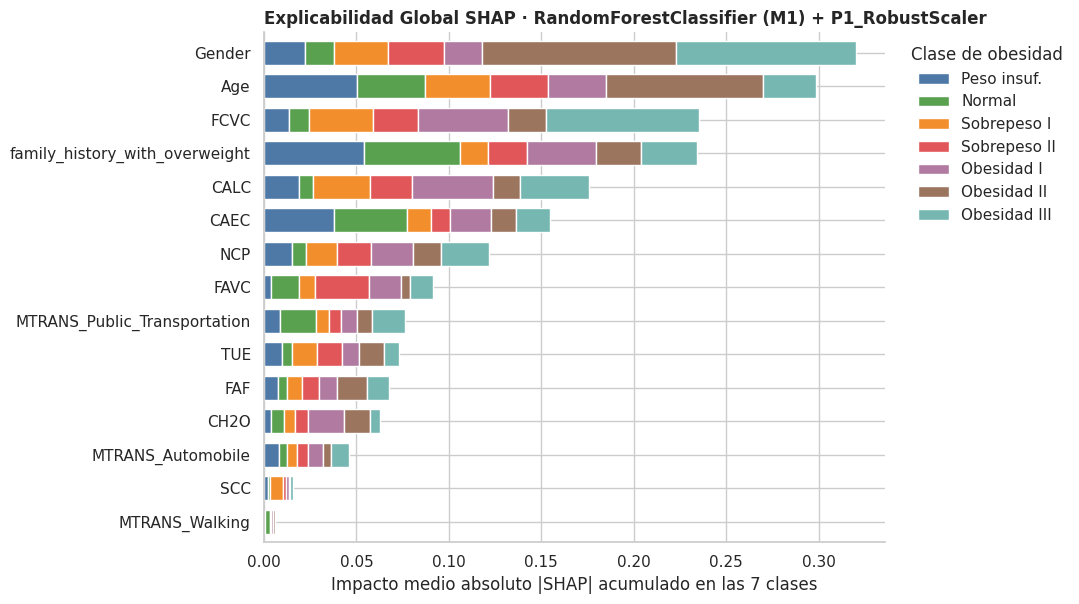

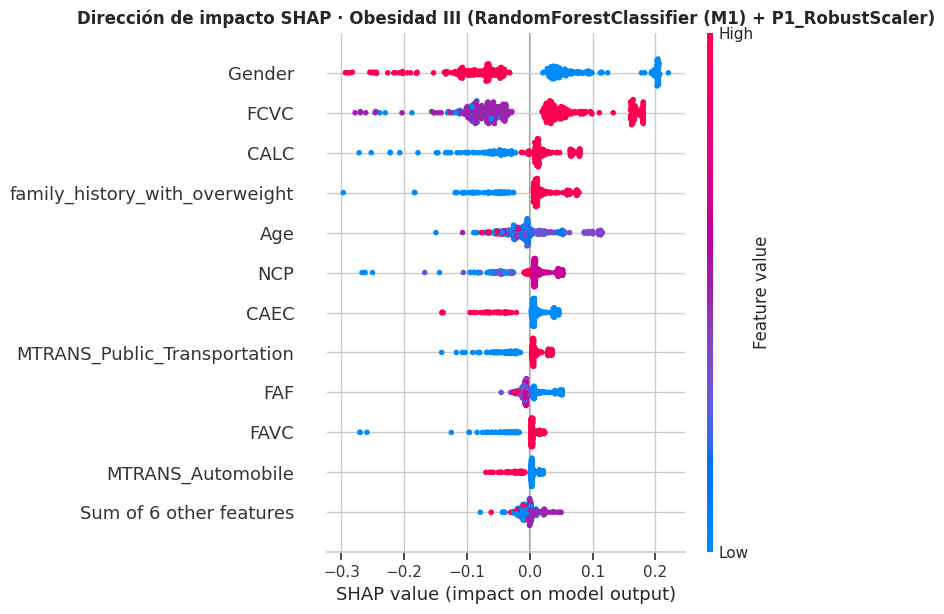

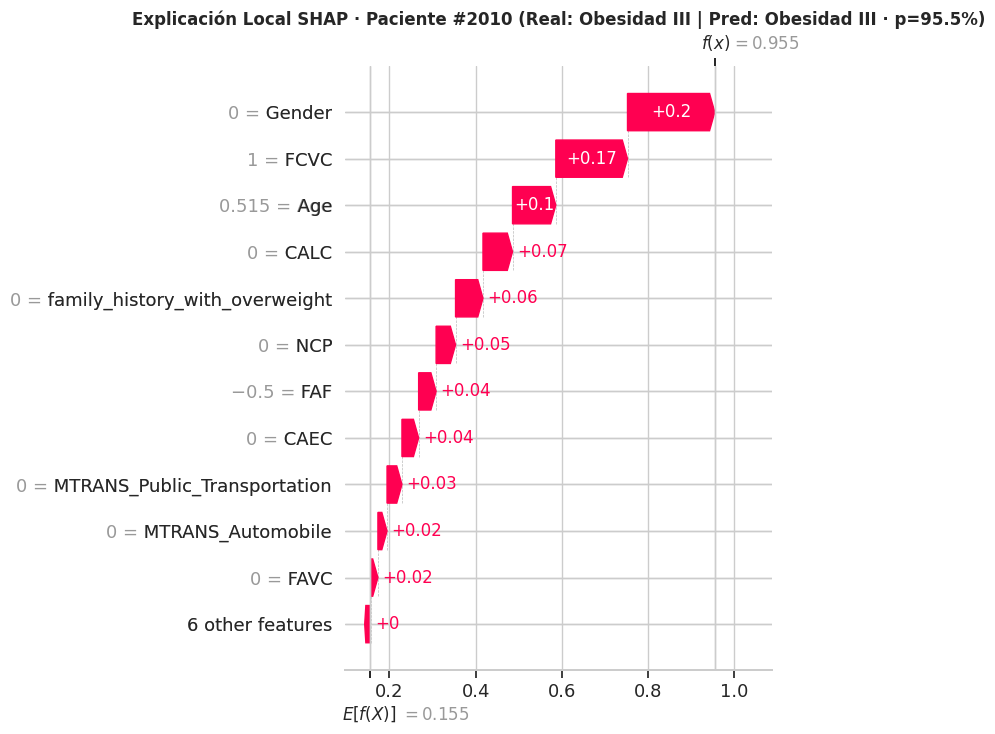

Gráficas y tabla SHAP guardadas en /content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico/modelos


In [57]:
prep_gan = gan_pipe.named_steps["prep"]
clf_gan = gan_pipe.named_steps["clf"]

# 1. Transformar entrenamiento y prueba al espacio exacto que ve el clasificador ganador
X_tr_arr = prep_gan.transform(X_train)
X_te_arr = prep_gan.transform(X_test)
nombres_shap = (
    list(prep_gan.get_feature_names_out())
    if hasattr(prep_gan, "get_feature_names_out")
    else [f"feat_{i}" for i in range(X_te_arr.shape[1])]
)
X_tr_shap = pd.DataFrame(X_tr_arr, columns=nombres_shap, index=X_train.index)
X_te_shap = pd.DataFrame(X_te_arr, columns=nombres_shap, index=X_test.index)

# 2. Seleccionar explainer automáticamente según la familia del ganador
es_arbol = hasattr(clf_gan, "estimators_") or clf_gan.__class__.__name__.startswith("XGB")
t0 = time.perf_counter()

if es_arbol:
    explainer_shap = shap.TreeExplainer(clf_gan)
    X_eval_shap = X_te_shap
    y_eval_shap = y_test
    raw_shap = explainer_shap.shap_values(X_eval_shap.values)
    tipo_explainer = "TreeExplainer (exacto)"
else:
    n_eval = min(100, len(X_te_shap))
    idx_eval_shap, _ = train_test_split(
        X_te_shap.index, train_size=n_eval, stratify=y_test, random_state=SEMILLA
    )
    X_eval_shap = X_te_shap.loc[idx_eval_shap]
    y_eval_shap = y_test.loc[idx_eval_shap]
    fondo_shap = shap.kmeans(X_tr_shap.values, 40)
    explainer_shap = shap.KernelExplainer(clf_gan.predict_proba, fondo_shap)
    raw_shap = explainer_shap.shap_values(X_eval_shap.values, nsamples=100)
    tipo_explainer = f"KernelExplainer (kmeans=40, n={n_eval})"

# 3. Normalizar salida multiclase a forma estándar (n_muestras, n_variables, 7_clases)
n_clases_shap = len(etiquetas_cortas)
if isinstance(raw_shap, list):
    vals_3d = np.stack([np.asarray(a, dtype=float) for a in raw_shap], axis=-1)
else:
    arr_s = np.asarray(raw_shap, dtype=float)
    if arr_s.ndim == 3 and arr_s.shape[2] == n_clases_shap:
        vals_3d = arr_s
    elif arr_s.ndim == 3 and arr_s.shape[0] == n_clases_shap:
        vals_3d = np.transpose(arr_s, (1, 2, 0))
    else:
        raise ValueError(f"Forma SHAP inesperada: {arr_s.shape}")

expected_vals = np.asarray(explainer_shap.expected_value, dtype=float).ravel()
print(f"SHAP listo ({tipo_explainer}) para {gan_alg} + {gan_prep} en {time.perf_counter() - t0:.2f} s | forma={vals_3d.shape}")

# 4. Tabla y Gráfica 1: Importancia global multiclase (media |SHAP| apilada por clase)
media_abs_clase = pd.DataFrame(
    np.mean(np.abs(vals_3d), axis=0),
    index=nombres_shap,
    columns=etiquetas_cortas,
)
media_abs_clase["Total_SHAP"] = media_abs_clase.sum(axis=1)
tabla_shap_global = media_abs_clase.sort_values("Total_SHAP", ascending=False)
tabla_shap_global.to_csv(CARPETA_MODELOS / "shap_importancia_global.csv", encoding="utf-8")
display(tabla_shap_global.head(12))

top_k = min(15, len(tabla_shap_global))
df_plot_shap = tabla_shap_global.head(top_k).drop(columns=["Total_SHAP"]).iloc[::-1]
paleta_clases = ["#4e79a7", "#59a14f", "#f28e2b", "#e15759", "#b07aa1", "#9c755f", "#76b7b2"]

fig, ax = plt.subplots(figsize=(11, 6.2))
df_plot_shap.plot(kind="barh", stacked=True, ax=ax, color=paleta_clases, width=0.72, edgecolor="white")
ax.set_xlabel("Impacto medio absoluto |SHAP| acumulado en las 7 clases")
ax.set_ylabel("")
ax.set_title(f"Explicabilidad Global SHAP · {gan_alg} + {gan_prep}", fontweight="bold", loc="left")
ax.legend(title="Clase de obesidad", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(CARPETA_MODELOS / "shap_global_ganador.png", dpi=180, bbox_inches="tight")
plt.show()

# 5. Gráfica 2: Beeswarm SHAP para la clase de mayor riesgo clínico (Obesidad III, clase 6)
clase_foco = 6
exp_ob3 = shap.Explanation(
    values=vals_3d[:, :, clase_foco],
    base_values=np.full(len(X_eval_shap), float(expected_vals[clase_foco])),
    data=X_eval_shap.values,
    feature_names=nombres_shap,
)
plt.figure(figsize=(10.5, 6))
shap.plots.beeswarm(exp_ob3, max_display=12, show=False)
plt.title(f"Dirección de impacto SHAP · {etiquetas_cortas[clase_foco]} ({gan_alg} + {gan_prep})", fontweight="bold")
plt.tight_layout()
plt.savefig(CARPETA_MODELOS / "shap_beeswarm_obesidad3_ganador.png", dpi=180, bbox_inches="tight")
plt.show()

# 6. Gráfica 3: Explicación local (Waterfall) para un paciente correctamente clasificado de alto riesgo
preds_eval = clf_gan.predict(X_eval_shap.values)
probs_eval = clf_gan.predict_proba(X_eval_shap.values)
candidatos_alto_riesgo = np.where((y_eval_shap.values == 6) & (preds_eval == 6))[0]
if len(candidatos_alto_riesgo) == 0:
    candidatos_alto_riesgo = np.where(y_eval_shap.values == preds_eval)[0]
pos_pac = int(candidatos_alto_riesgo[0]) if len(candidatos_alto_riesgo) > 0 else 0
clase_pred_pac = int(preds_eval[pos_pac])
clase_real_pac = int(y_eval_shap.iloc[pos_pac])
prob_pac = float(probs_eval[pos_pac, clase_pred_pac])

exp_local = shap.Explanation(
    values=vals_3d[pos_pac, :, clase_pred_pac],
    base_values=float(expected_vals[clase_pred_pac]),
    data=X_eval_shap.iloc[pos_pac].values,
    feature_names=nombres_shap,
)
plt.figure(figsize=(10.5, 5.8))
shap.plots.waterfall(exp_local, max_display=12, show=False)
plt.title(
    f"Explicación Local SHAP · Paciente #{X_eval_shap.index[pos_pac]} "
    f"(Real: {etiquetas_cortas[clase_real_pac]} | Pred: {etiquetas_cortas[clase_pred_pac]} · p={prob_pac:.1%})",
    fontweight="bold",
)
plt.tight_layout()
plt.savefig(CARPETA_MODELOS / "shap_local_paciente_ganador.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Gráficas y tabla SHAP guardadas en {CARPETA_MODELOS}")